# 3 (KhangBao): Làm sạch biên & Lọc nhiễu (ENN, RENN, AllKNN, Tomek Links, NCR, IHT)


## 3.1 Khởi tạo môi trường chung

In [1]:
# === CELL KHOI TAO MOI TRUONG CHUNG ===
import os, sys

# Them thu muc goc vao sys.path de import duoc module src.utils
root_dir = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if root_dir not in sys.path:
    sys.path.insert(0, root_dir)

from src.utils import (
    RANDOM_STATE,
    load_synthetic_data,
    load_real_data,
    get_all_undersamplers,
    get_benchmark_models,
    plot_resampled_comparison,
    plot_decision_boundary,
    plot_pr_curve,
    evaluate_sampler_and_model
)
print('Khoi tao thanh cong! Thu muc goc:', root_dir)

Khoi tao thanh cong! Thu muc goc: D:\pattern_recognition\PR_Seminar_Undersampling


In [2]:
# === THU VIEN BO SUNG RIENG CHO PHAN 3 ===
import time
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import NearestNeighbors

from imblearn.under_sampling import (
    EditedNearestNeighbours,
    RepeatedEditedNearestNeighbours,
    TomekLinks,
    InstanceHardnessThreshold
)
from src.utils import save_figure, save_table

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

## 3.2 Tổng quan: Nhóm phương pháp làm sạch (Cleaning methods)

Theo cách phân loại của Chương 3, các kỹ thuật undersampling chia làm hai nhóm:

* **Fixed methods** – giảm lớp đa số về một số lượng *cố định* cho trước (RUS, ClusterCentroids – Phần 2).
* **Cleaning methods** – không ấn định số lượng, mà loại bỏ các mẫu đa số *thỏa một tiêu chí* (thường dựa trên láng giềng gần). Số mẫu bị xóa phụ thuộc hoàn toàn vào cấu trúc của dữ liệu.

Phần này trình bày chiến lược **xóa các quan sát nhiễu và nằm sát biên** (*Strategies for removing noisy observations*). Theo ẩn dụ Romeo & Juliet của sách: nhà vua loại bớt những người Capulet (lớp đa số) *sống gần* hoặc *thân thiết* với người Montague (lớp thiểu số), để tách hai dòng họ ra xa nhau và giảm xung đột.

### Bốn loại mẫu theo vị trí (Kubat & Matwin, 1997)

| Loại mẫu | Đặc điểm | Nhóm phương pháp nhắm tới |
|---|---|---|
| **Safe** (an toàn) | Nằm sâu trong vùng của lớp mình | Giữ lại |
| **Borderline** (sát biên) | Gần biên quyết định, chỉ cần nhiễu nhỏ là bị phân loại sai | ENN, Tomek Links, NCR |
| **Noise** (nhiễu) | Nằm lọt hẳn vào vùng của lớp kia | ENN, RENN, AllKNN, IHT |
| **Redundant** (dư thừa) | Xa biên, rất dễ phân loại | CNN, OSS (Phần 2 – xóa mẫu dễ) |

### Cơ chế "mở rộng lề" (margin expansion)

1. Xóa các mẫu đa số nằm trong vùng chồng lấn (*class overlap*) → khoảng cách từ mẫu thiểu số đến mẫu đa số gần nhất **tăng lên** → lề giữa hai lớp rộng hơn.
2. Bộ phân loại không còn bị các mẫu đa số "lấn sân" kéo biên về phía lớp thiểu số → biên quyết định **dịch về phía lớp đa số** → Recall lớp thiểu số tăng, đổi lại Precision có thể giảm.
3. Vì thường chỉ xóa một lượng nhỏ, các phương pháp làm sạch **không cân bằng được dữ liệu** (ngoại trừ IHT) → hay được ghép với oversampling: SMOTEENN, SMOTETomek (Phần 4).

### Tóm tắt 6 thuật toán của phần này

| Thuật toán | Bài báo gốc | Tiêu chí loại bỏ mẫu đa số | Kiểm soát tỉ lệ đầu ra? |
|---|---|---|---|
| **ENN** | Wilson (1972) | Có láng giềng k-NN khác lớp (tất cả / đa số) | Không |
| **RENN** | Tomek (1976b) | Lặp ENN đến khi không còn gì để xóa | Không |
| **AllKNN** | Tomek (1976b) | Chạy ENN lần lượt với k = 1, 2, …, K | Không |
| **Tomek Links** | Tomek (1976a) | Là láng giềng gần nhất *của nhau* nhưng khác lớp | Không |
| **NCR** | Laurikkala (2001) | ENN + xóa láng giềng đa số của mẫu thiểu số bị phân loại sai | Không |
| **IHT** | Smith, Martinez & Giraud-Carrier (2014) | Xác suất dự đoán đúng lớp (qua cross-validation) thấp – "mẫu khó" | Có (`sampling_strategy`) |

## 3.3 Chuẩn bị dữ liệu 2D và các hàm bổ trợ

Dùng đúng pipeline chung của nhóm: `load_synthetic_data(class_sep=0.79)` – 10.000 mẫu 2 chiều, tỉ lệ 1:99, `DATA_RANDOM_STATE = 81` giống sách. Mọi thuật toán **chỉ chạy trên tập train** (đã chia `stratify`) để tránh rò rỉ dữ liệu; tập test giữ nguyên phân phối gốc để đánh giá ở mục 3.10.

Các sampler lấy từ `get_all_undersamplers()` (cấu hình mặc định chung của nhóm). Mọi sampler làm sạch trong imbalanced-learn đều có thuộc tính `sample_indices_` (chỉ số các mẫu được giữ lại) – ta dùng nó để tô màu chính xác những mẫu bị xóa.

In [3]:
X_train, X_test, y_train, y_test, X_full, y_full = load_synthetic_data(class_sep=0.79)

# Dung numpy array de truy cap theo vi tri (sample_indices_ la chi so vi tri)
X_tr, y_tr = X_train.values, y_train.values
X_te, y_te = X_test.values, y_test.values

samplers = get_all_undersamplers(include_slow=False)
models = get_benchmark_models()


def count_classes(y):
    """Dem so mau moi lop, tra ve dict {int: int} de in gon gang."""
    return {int(k): int(v) for k, v in sorted(Counter(y).items())}


print("Train:", count_classes(y_tr), "| Test:", count_classes(y_te))
print("Ti le mat can bang (train): 1 :", round((y_tr == 0).sum() / (y_tr == 1).sum()))

Train: {0: 7920, 1: 80} | Test: {0: 1980, 1: 20}
Ti le mat can bang (train): 1 : 99


In [4]:
# === HAM BO TRO RIENG CUA PHAN 3 ===
XLIM, YLIM = (-3, 3), (-5, 4)   # Dong bo voi plot_resampled_comparison() trong src.utils
cleaning_results = {}           # Luu ket qua tung thuat toan de so sanh o muc 3.10


def removed_mask(sampler, n_samples):
    """Tra ve mask True cho cac mau bi sampler loai bo (dua tren sample_indices_)."""
    mask = np.ones(n_samples, dtype=bool)
    mask[sampler.sample_indices_] = False
    return mask


def run_cleaning(name, sampler):
    """Chay fit_resample tren tap train, do thoi gian va luu ket qua vao cleaning_results."""
    start = time.perf_counter()
    X_res, y_res = sampler.fit_resample(X_tr, y_tr)
    elapsed = time.perf_counter() - start
    removed = removed_mask(sampler, len(y_tr))
    cleaning_results[name] = {"X_res": X_res, "y_res": y_res, "removed": removed, "time": elapsed}
    print(f"{name}: {count_classes(y_tr)} -> {count_classes(y_res)} "
          f"| loai {removed.sum()} mau | {elapsed:.3f}s")
    return X_res, y_res, removed


def compare_plot(X_res, y_res, method_name):
    """Goi ham chung plot_resampled_comparison() (y dang Series de tieu de hien so nguyen)."""
    return plot_resampled_comparison(X_tr, pd.Series(y_tr), X_res, pd.Series(y_res), method_name=method_name)


def plot_removed_samples(X, y, removed, title, ax=None, xlim=XLIM, ylim=YLIM):
    """Ve tap goc va to do cac mau bi loai bo de thay vung bien duoc 'lam sach'."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 5))
    kept_maj = (y == 0) & ~removed
    ax.scatter(X[kept_maj, 0], X[kept_maj, 1], marker="v", s=10, c="lightgray", label="Majority kept")
    ax.scatter(X[removed & (y == 0), 0], X[removed & (y == 0), 1], marker="o", s=28,
               facecolors="none", edgecolors="red", linewidths=1.1,
               label=f"Majority removed ({(removed & (y == 0)).sum()})")
    ax.scatter(X[(y == 1) & ~removed, 0], X[(y == 1) & ~removed, 1], marker="X", s=40, c="navy", label="Minority")
    if (removed & (y == 1)).any():
        ax.scatter(X[removed & (y == 1), 0], X[removed & (y == 1), 1], marker="X", s=40, c="red",
                   label=f"Minority removed ({(removed & (y == 1)).sum()})")
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_title(title)
    ax.set_xlabel("feature_1")
    ax.set_ylabel("feature_2")
    ax.legend(loc="lower right", fontsize=8)
    return ax


def nearest_opposite_distance(X, y):
    """Khoang cach tu moi mau thieu so den mau da so gan nhat (thuoc do 'do rong le')."""
    nn = NearestNeighbors(n_neighbors=1).fit(X[y == 0])
    dist, _ = nn.kneighbors(X[y == 1])
    return dist.ravel()

## 3.4 Edited Nearest Neighbours (ENN)

### 3.4.1 Lý thuyết

**Ý tưởng** (Wilson, 1972): nếu các láng giềng gần nhất của một mẫu lại thuộc lớp khác, mẫu đó nhiều khả năng là **nhiễu** hoặc nằm **sát biên** → xóa nó để "biên tập" (*edit*) lại tập huấn luyện. Trong imbalanced-learn chỉ các lớp được chọn mới bị xét – mặc định `sampling_strategy='auto'` nghĩa là *mọi lớp trừ lớp thiểu số*.

Gọi $N_k(x_i)$ là tập $k$ láng giềng gần nhất của $x_i$ (không tính chính nó). Mẫu đa số $x_i$ bị **xóa** nếu:

* `kind_sel='all'` (chặt – mặc định): $\exists\, x_j \in N_k(x_i):\ y_j \neq y_i$ → chỉ cần **một** láng giềng khác lớp.
* `kind_sel='mode'` (lỏng): $\operatorname{mode}\{\,y_j : x_j \in N_k(x_i)\,\} \neq y_i$ → **đa số** láng giềng khác lớp.

**Thuật toán**

```
Input : tập D, số láng giềng k, tiêu chí kind_sel
1. Fit k-NN trên toàn bộ D
2. Với mỗi mẫu x_i thuộc lớp cần undersample:
       tìm N_k(x_i); nếu vi phạm tiêu chí kind_sel -> đánh dấu xóa
3. Trả về D \ {các mẫu bị đánh dấu}        # xóa đồng thời trong MỘT lượt
```

* **Độ phức tạp:** một lần truy vấn k-NN cho $n$ mẫu – $O(n^2 d)$ nếu brute-force, xấp xỉ $O(n \log n)$ với KD-tree/Ball-tree khi số chiều $d$ nhỏ.
* **Tham số chính:** `n_neighbors` (k càng lớn → vùng xét càng rộng → xóa càng nhiều), `kind_sel`.
* **Lưu ý:** là phương pháp dựa trên khoảng cách nên dữ liệu thực tế **phải được chuẩn hóa** (`load_real_data()` đã dùng `StandardScaler`).

### 3.4.2 Áp dụng ENN với imbalanced-learn

ENN: {0: 7920, 1: 80} -> {0: 7827, 1: 80} | loai 93 mau | 0.017s


Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_enn_comparison.png


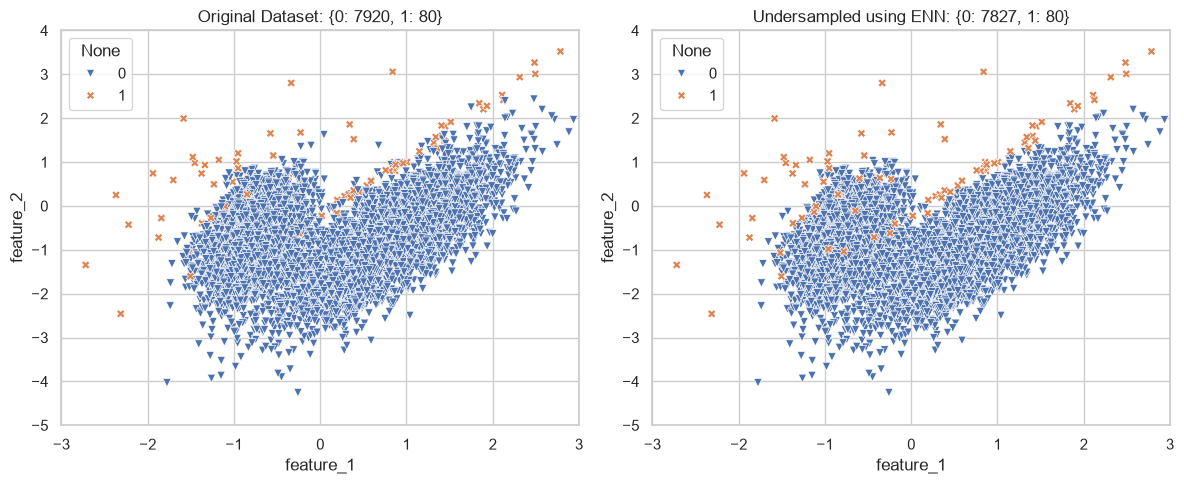

In [5]:
enn = samplers["ENN"]   # EditedNearestNeighbours(n_neighbors=3, kind_sel='all')
X_enn, y_enn, removed_enn = run_cleaning("ENN", enn)

fig = compare_plot(X_enn, y_enn, "ENN")
save_figure(fig, "tv3_enn_comparison")
plt.show()

Lớp đa số chỉ mất khoảng 1% mẫu nên hai đồ thị trông gần giống nhau. Để thấy rõ **ENN xóa ở đâu**, ta tô đỏ các mẫu bị loại và phóng to một mẫu bị xóa cùng 3 láng giềng của nó:

Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_enn_removed_zoom.png


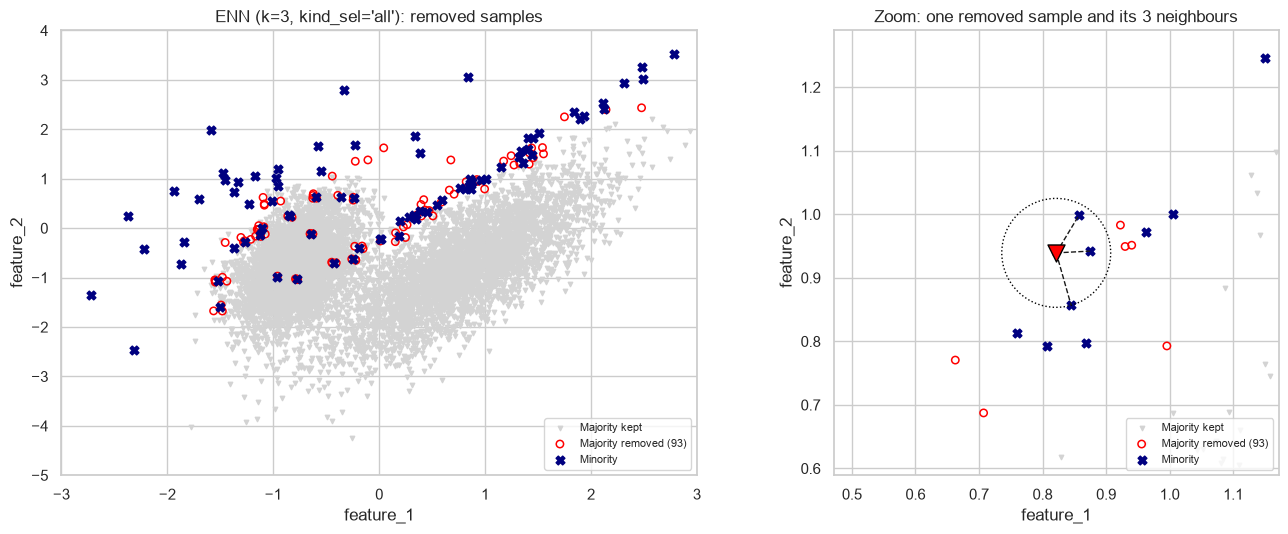

Nhan cua 3 lang gieng cua mau vi du: [1 1 1] -> co lang gieng khac lop -> bi xoa


In [6]:
# Chon mot mau da so bi xoa co nhieu lang gieng thieu so nhat de minh hoa
nn_enn = NearestNeighbors(n_neighbors=enn.n_neighbors + 1).fit(X_tr)
removed_idx = np.flatnonzero(removed_enn)
neigh_idx = nn_enn.kneighbors(X_tr[removed_idx], return_distance=False)[:, 1:]
example = removed_idx[np.argmax((y_tr[neigh_idx] == 1).sum(axis=1))]
example_neigh = nn_enn.kneighbors(X_tr[[example]], return_distance=False)[0, 1:]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_removed_samples(X_tr, y_tr, removed_enn, "ENN (k=3, kind_sel='all'): removed samples", ax=axes[0])

cx, cy = X_tr[example]
plot_removed_samples(X_tr, y_tr, removed_enn, "Zoom: one removed sample and its 3 neighbours",
                     ax=axes[1], xlim=(cx - 0.35, cx + 0.35), ylim=(cy - 0.35, cy + 0.35))
for j in example_neigh:
    axes[1].plot([cx, X_tr[j, 0]], [cy, X_tr[j, 1]], "k--", lw=1)
axes[1].scatter(cx, cy, marker="v", s=150, c="red", edgecolors="black", zorder=5)
radius = np.linalg.norm(X_tr[example_neigh] - X_tr[example], axis=1).max()
axes[1].add_patch(plt.Circle((cx, cy), radius, fill=False, ls=":", color="black"))
axes[1].set_aspect("equal")
plt.tight_layout()
save_figure(fig, "tv3_enn_removed_zoom")
plt.show()

print("Nhan cua 3 lang gieng cua mau vi du:", y_tr[example_neigh], "-> co lang gieng khac lop -> bi xoa")

### 3.4.3 Tự cài đặt ENN để kiểm chứng cơ chế

Cài đặt lại đúng định nghĩa ở 3.4.1 bằng `NearestNeighbors` thuần của scikit-learn và so sánh với kết quả của imbalanced-learn:

In [7]:
def manual_enn(X, y, k=3, kind_sel="all", maj_class=0):
    """ENN tu cai dat: xoa mau lop maj_class co lang gieng khac lop."""
    nn = NearestNeighbors(n_neighbors=k + 1).fit(X)
    maj_idx = np.flatnonzero(y == maj_class)
    neigh = nn.kneighbors(X[maj_idx], return_distance=False)[:, 1:]  # bo chinh no
    n_diff = (y[neigh] != maj_class).sum(axis=1)
    bad = n_diff > 0 if kind_sel == "all" else n_diff > k / 2
    removed = np.zeros(len(y), dtype=bool)
    removed[maj_idx[bad]] = True
    return removed


for kind in ["all", "mode"]:
    sampler = EditedNearestNeighbours(n_neighbors=3, kind_sel=kind)
    sampler.fit_resample(X_tr, y_tr)
    lib = removed_mask(sampler, len(y_tr))
    mine = manual_enn(X_tr, y_tr, k=3, kind_sel=kind)
    print(f"kind_sel='{kind}': imblearn xoa {lib.sum()}, tu cai dat xoa {mine.sum()}, "
          f"trung khop hoan toan: {np.array_equal(lib, mine)}")

kind_sel='all': imblearn xoa 93, tu cai dat xoa 93, trung khop hoan toan: True
kind_sel='mode': imblearn xoa 17, tu cai dat xoa 17, trung khop hoan toan: True


### 3.4.4 Ảnh hưởng của `n_neighbors` và `kind_sel`

kind_sel,all,mode
n_neighbors,,
1,31,31
3,93,17
5,149,15
10,235,7
25,440,0


Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_enn_params.png


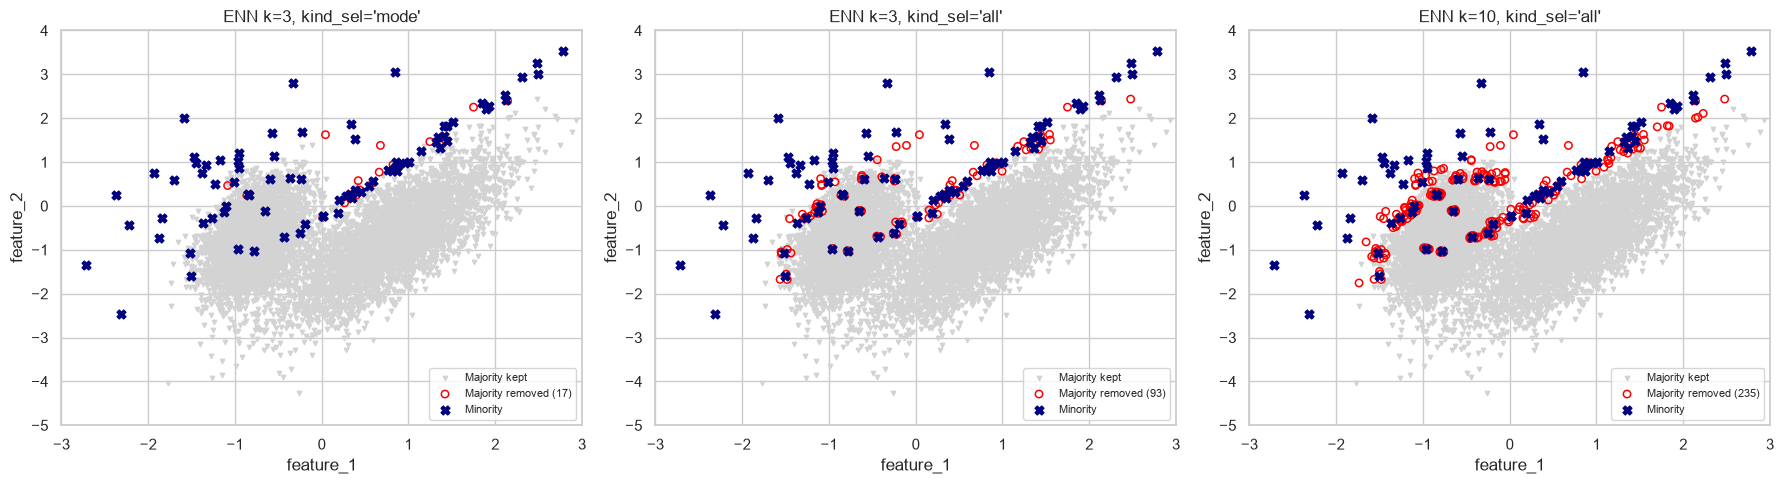

In [8]:
rows = []
for k in [1, 3, 5, 10, 25]:
    for kind in ["all", "mode"]:
        s = EditedNearestNeighbours(n_neighbors=k, kind_sel=kind)
        _, y_res = s.fit_resample(X_tr, y_tr)
        rows.append({"n_neighbors": k, "kind_sel": kind,
                     "Majority removed": int((y_tr == 0).sum() - (y_res == 0).sum())})
enn_param_df = pd.DataFrame(rows).pivot(index="n_neighbors", columns="kind_sel", values="Majority removed")
display(enn_param_df)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (k, kind) in zip(axes, [(3, "mode"), (3, "all"), (10, "all")]):
    s = EditedNearestNeighbours(n_neighbors=k, kind_sel=kind)
    s.fit_resample(X_tr, y_tr)
    plot_removed_samples(X_tr, y_tr, removed_mask(s, len(y_tr)), f"ENN k={k}, kind_sel='{kind}'", ax=ax)
plt.tight_layout()
save_figure(fig, "tv3_enn_params")
plt.show()

**Nhận xét ENN**

* `kind_sel='mode'` chỉ xóa các mẫu *nhiễu thực sự* (bị đa số láng giềng "bao vây"); `kind_sel='all'` xóa thêm cả mẫu *sát biên* → lề rộng hơn.
* Tăng `n_neighbors` làm số mẫu bị xóa tăng gần tuyến tính: vùng "làm sạch" quanh mỗi mẫu thiểu số rộng ra (sách dùng `n_neighbors=200` để có hiệu ứng thấy rõ trên đồ thị).
* Các mẫu bị xóa tập trung hoàn toàn quanh các cụm thiểu số – đúng như mục tiêu "tách hai dòng họ".

## 3.5 Repeated Edited Nearest Neighbours (RENN)

### 3.5.1 Lý thuyết

ENN chỉ chạy **một lượt**: sau khi xóa lớp mẫu sát biên đầu tiên, một số mẫu đa số ở "lớp thứ hai" lại trở thành sát biên nhưng không được xét. **RENN** (Tomek, 1976b – *"An Experiment with the Edited Nearest-Neighbor Rule"*) lặp lại ENN, **fit lại k-NN trên tập vừa làm sạch** ở mỗi vòng, cho tới khi gặp một trong các điều kiện dừng:

1. Không còn mẫu nào bị xóa (hội tụ);
2. Đạt số vòng tối đa `max_iter` (mặc định 100);
3. Lớp đa số trở nên ít hơn lớp thiểu số;
4. Một lớp bị xóa hết.

```
D_0 = D
for t = 1..max_iter:
    D_t = ENN(D_{t-1})
    if |D_t| == |D_{t-1}| or (điều kiện 3, 4): break
return D_t
```

→ RENN làm sạch biên **mạnh hơn** ENN; số vòng thực tế lưu trong thuộc tính `n_iter_`.

RENN: {0: 7920, 1: 80} -> {0: 7780, 1: 80} | loai 140 mau | 0.083s
So vong lap thuc te n_iter_ = 6


Vong lap,1,2,3,4,5,6
Tong so mau da xoa,93,125,135,139,140,140


Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_renn_comparison.png


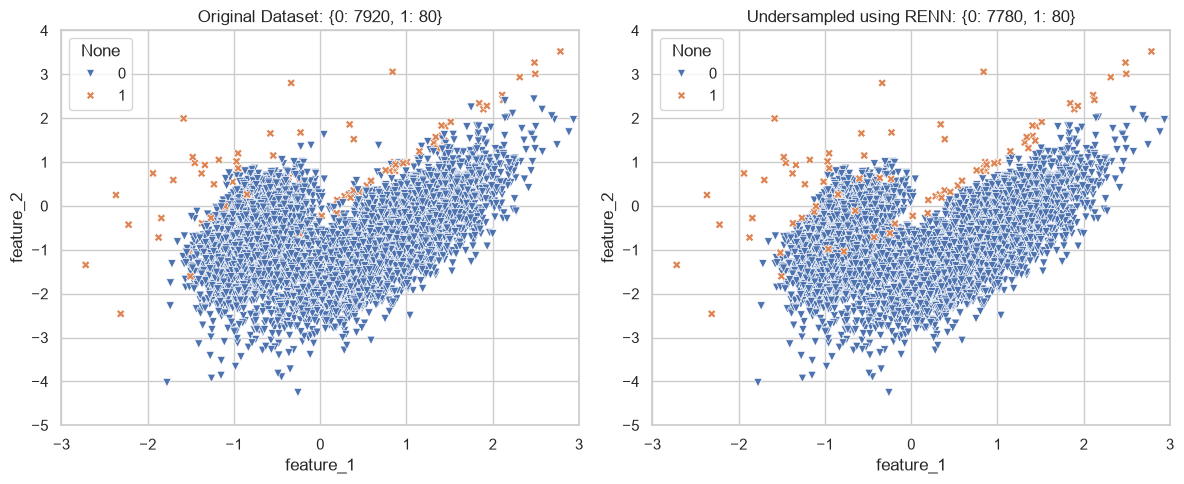

In [9]:
renn = samplers["RENN"]
X_renn, y_renn, removed_renn = run_cleaning("RENN", renn)
print("So vong lap thuc te n_iter_ =", renn.n_iter_)

# So mau bi xoa tich luy theo tung vong lap
cum_removed = []
for it in range(1, renn.n_iter_ + 1):
    s = RepeatedEditedNearestNeighbours(max_iter=it)
    _, y_res = s.fit_resample(X_tr, y_tr)
    cum_removed.append(int(len(y_tr) - len(y_res)))
display(pd.DataFrame({"Vong lap": range(1, renn.n_iter_ + 1), "Tong so mau da xoa": cum_removed}).set_index("Vong lap").T)

fig = compare_plot(X_renn, y_renn, "RENN")
save_figure(fig, "tv3_renn_comparison")
plt.show()

## 3.6 AllKNN

### 3.6.1 Lý thuyết

Cũng trong Tomek (1976b), **All k-NN** chạy ENN **tuần tự với kích thước lân cận tăng dần** $k = 1, 2, \dots, K$ (trong imbalanced-learn `n_neighbors=3` → $k = 1, 2, 3$), mỗi bước áp dụng trên tập đã làm sạch ở bước trước:

```
D_0 = D
for k = 1..K:
    D_k = ENN(D_{k-1}, n_neighbors = k)
    if lớp đa số trở thành thiểu số (và allow_minority=False) or một lớp biến mất: break
return D_K
```

* Một mẫu chỉ được giữ lại nếu nó "sống sót" ở **mọi** kích thước lân cận → kết quả **ít nhạy** với việc chọn một giá trị k cụ thể.
* Khác RENN: RENN lặp với *cùng* k đến khi hội tụ; AllKNN lặp *đúng K lần* với k thay đổi.

AllKNN: {0: 7920, 1: 80} -> {0: 7806, 1: 80} | loai 114 mau | 0.035s


Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_allknn_comparison.png


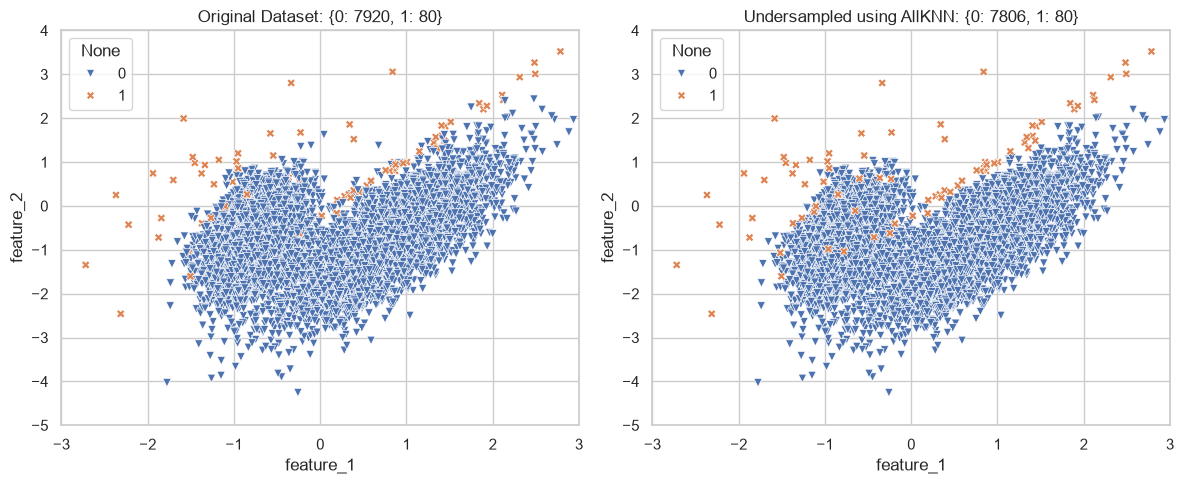

In [10]:
allknn = samplers["AllKNN"]
X_allknn, y_allknn, removed_allknn = run_cleaning("AllKNN", allknn)

fig = compare_plot(X_allknn, y_allknn, "AllKNN")
save_figure(fig, "tv3_allknn_comparison")
plt.show()

### 3.6.2 So sánh họ ENN: ENN vs RENN vs AllKNN

Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_enn_family_removed.png


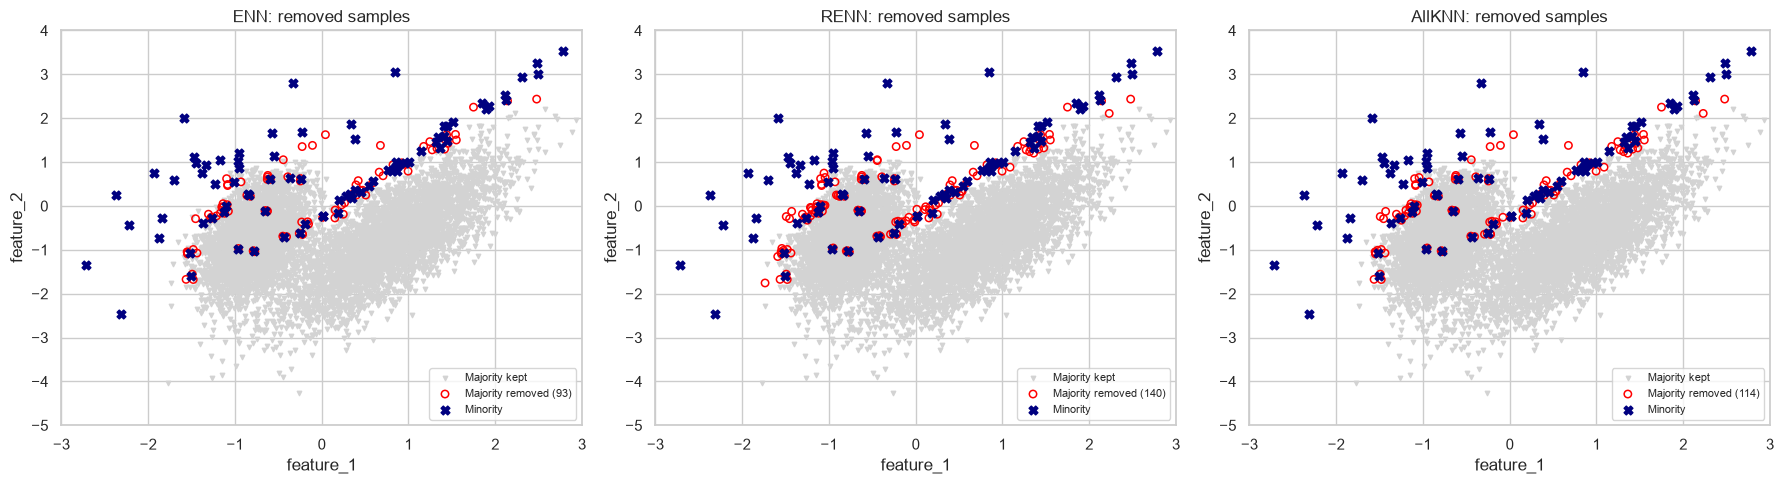

Mau bi ENN xoa cung bi RENN xoa:   True
Mau bi ENN xoa cung bi AllKNN xoa: True


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, ["ENN", "RENN", "AllKNN"]):
    plot_removed_samples(X_tr, y_tr, cleaning_results[name]["removed"], f"{name}: removed samples", ax=ax)
plt.tight_layout()
save_figure(fig, "tv3_enn_family_removed")
plt.show()

print("Mau bi ENN xoa cung bi RENN xoa:  ", np.all(removed_renn[removed_enn]))
print("Mau bi ENN xoa cung bi AllKNN xoa:", np.all(removed_allknn[removed_enn]))

**Nhận xét họ ENN:** mức độ làm sạch tăng dần ENN < AllKNN < RENN. Mọi mẫu ENN xóa đều bị RENN xóa (vòng 1 của RENN chính là ENN); RENN tiếp tục "ăn" sâu thêm vào vùng đa số quanh các cụm thiểu số. Đổi lại, chi phí tính toán tăng theo số vòng lặp.

## 3.7 Tomek Links

### 3.7.1 Lý thuyết

**Định nghĩa** (Tomek, 1976a – *"Two Modifications of CNN"*): hai mẫu $x_i, x_j$ tạo thành một **Tomek link** nếu

$$y_i \neq y_j \quad\text{và}\quad \nexists\, x_l:\ d(x_i, x_l) < d(x_i, x_j)\ \ \text{hoặc}\ \ d(x_j, x_l) < d(x_i, x_j)$$

tức là chúng **khác lớp** nhưng lại là **láng giềng gần nhất của nhau** (mutual 1-NN). Trực giác: *"hai điểm khác lớp thì không nên là hàng xóm gần nhất của nhau"* – nếu có, một trong hai là nhiễu, hoặc cả hai nằm ngay trên biên. Trong ẩn dụ của sách: nhà vua loại những người Capulet có *bạn thân nhất* là người Montague.

**Cách xóa** (tham số `sampling_strategy`):

* `'auto'` (mặc định): chỉ xóa phần tử **thuộc lớp đa số** trong mỗi link → undersampling.
* `'all'`: xóa **cả hai** phần tử → làm sạch dữ liệu (thường dùng sau SMOTE – SMOTETomek, Phần 4).

**Đặc điểm**

* Mỗi điểm thuộc tối đa một link (vì 1-NN là duy nhất) → số mẫu bị xóa **rất ít**, Tomek Links là phương pháp "nhẹ tay" nhất trong nhóm.
* Cần tính láng giềng gần nhất cho mọi điểm (về bản chất là khoảng cách cặp) → tốn tài nguyên với dữ liệu lớn; Batista và cộng sự (2004) khuyến nghị chạy trên tập dữ liệu đã được thu gọn.

TomekLinks: {0: 7920, 1: 80} -> {0: 7898, 1: 80} | loai 22 mau | 0.013s


Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_tomek_comparison.png


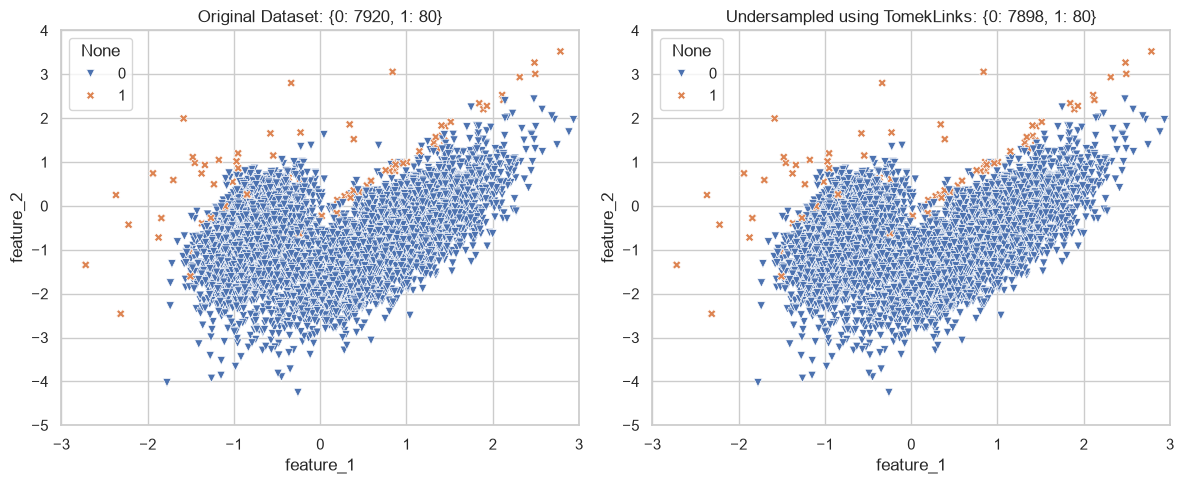

In [12]:
tl = samplers["TomekLinks"]
X_tl, y_tl, removed_tl = run_cleaning("TomekLinks", tl)

fig = compare_plot(X_tl, y_tl, "TomekLinks")
save_figure(fig, "tv3_tomek_comparison")
plt.show()

### 3.7.2 Tự phát hiện Tomek links và minh họa (tương tự Hình 3.14 trong sách)

So Tomek links tim duoc: 22
Tu cai dat trung khop voi imblearn ('auto'): True


Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_tomek_links_zoom.png


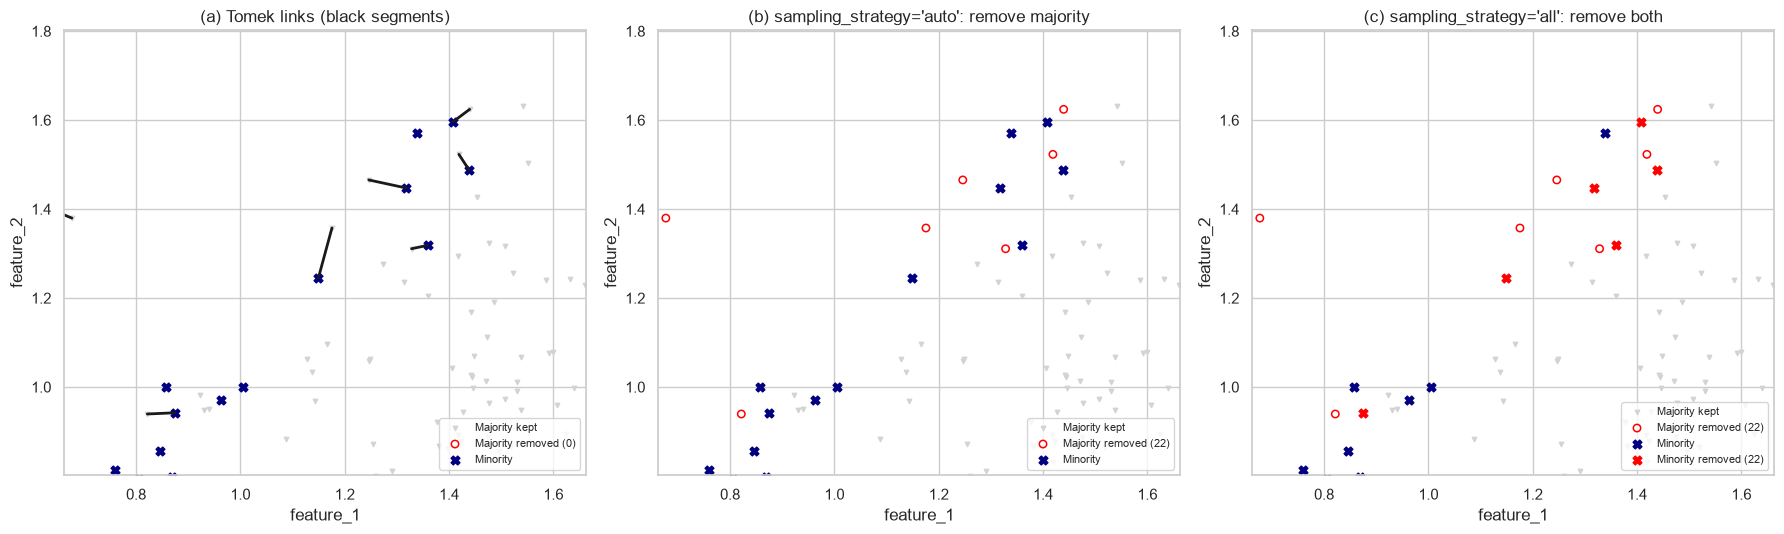

'auto' xoa: {0: 22} | 'all' xoa: {0: 22, 1: 22}


In [13]:
# Tomek link <=> hai diem la 1-NN cua nhau va khac lop
nn1 = NearestNeighbors(n_neighbors=2).fit(X_tr)
nn_of = nn1.kneighbors(X_tr, return_distance=False)[:, 1]
in_link = (y_tr != y_tr[nn_of]) & (nn_of[nn_of] == np.arange(len(y_tr)))
links = np.array(sorted({tuple(sorted((i, nn_of[i]))) for i in np.flatnonzero(in_link)}))

print("So Tomek links tim duoc:", len(links))
print("Tu cai dat trung khop voi imblearn ('auto'):", np.array_equal(in_link & (y_tr == 0), removed_tl))

tl_all = TomekLinks(sampling_strategy="all")
tl_all.fit_resample(X_tr, y_tr)
removed_tl_all = removed_mask(tl_all, len(y_tr))

# Chon vung zoom co mat do Tomek link cao nhat
mids = X_tr[links].mean(axis=1)
density = (np.linalg.norm(mids[:, None] - mids[None], axis=2) < 0.5).sum(axis=1)
zx, zy = mids[np.argmax(density)]
zoom = dict(xlim=(zx - 0.5, zx + 0.5), ylim=(zy - 0.5, zy + 0.5))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
plot_removed_samples(X_tr, y_tr, np.zeros(len(y_tr), dtype=bool), "(a) Tomek links (black segments)", ax=axes[0], **zoom)
for i, j in links:
    axes[0].plot(X_tr[[i, j], 0], X_tr[[i, j], 1], "k-", lw=2)
plot_removed_samples(X_tr, y_tr, removed_tl, "(b) sampling_strategy='auto': remove majority", ax=axes[1], **zoom)
plot_removed_samples(X_tr, y_tr, removed_tl_all, "(c) sampling_strategy='all': remove both", ax=axes[2], **zoom)
plt.tight_layout()
save_figure(fig, "tv3_tomek_links_zoom")
plt.show()

print("'auto' xoa:", count_classes(y_tr[removed_tl]), "| 'all' xoa:", count_classes(y_tr[removed_tl_all]))

**Nhận xét Tomek Links:** chỉ khoảng 20 mẫu đa số bị xóa – ít nhất trong cả nhóm. Với `'all'`, 22 mẫu thiểu số cũng bị xóa – **hơn 1/4** lớp thiểu số vốn đã rất ít! → **không nên** dùng `'all'` trực tiếp trên dữ liệu mất cân bằng nặng, chỉ nên dùng sau khi đã oversampling.

## 3.8 Neighbourhood Cleaning Rule (NCR)

### 3.8.1 Lý thuyết

**Ý tưởng** (Laurikkala, 2001): ENN chỉ nhìn từ phía mẫu đa số ("tôi có hàng xóm khác lớp không?"). NCR bổ sung **góc nhìn từ phía mẫu thiểu số**: *"những mẫu đa số nào đang làm mẫu thiểu số này bị phân loại sai?"* – rồi xóa chúng. Trong ẩn dụ: nhà vua xem xét hàng xóm của người Montague và loại những người Capulet xuất hiện trong số láng giềng gần nhất của họ. NCR đặt trọng tâm vào **làm sạch dữ liệu** hơn là giảm kích thước.

Gọi $C$ là lớp thiểu số, $O$ là các lớp còn lại:

```
Input : D, k = 3, threshold_cleaning = 0.5
1. A1 <- các mẫu thuộc O bị xóa bởi ENN(k, kind_sel='mode')        # bước lọc nhiễu
2. Với mỗi mẫu c ∈ C:
       nếu k-NN (fit trên D) dự đoán sai c:
           A2 <- A2 ∪ {láng giềng của c thuộc lớp o ∈ O với |o| > 0.5·|C|}
3. Trả về D \ (A1 ∪ A2)
```

* Điều kiện $|o| > \text{threshold\_cleaning}\cdot|C|$ tránh xóa mẫu của những lớp vốn cũng nhỏ (quan trọng khi bài toán đa lớp).
* Bước 1 dùng `kind_sel='mode'` (chỉ xóa mẫu bị *đa số* láng giềng phủ định) nên "nhẹ tay" hơn ENN mặc định; bước 2 bù lại bằng cách làm sạch đúng vùng quanh các mẫu thiểu số khó.

NCR: {0: 7920, 1: 80} -> {0: 7823, 1: 80} | loai 97 mau | 0.025s
Lop duoc xet lam sach (classes_to_clean_): [0]
A1 (buoc ENN): 17 mau | A2 (buoc lam sach lang gieng): 80 mau


Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_ncr_comparison.png


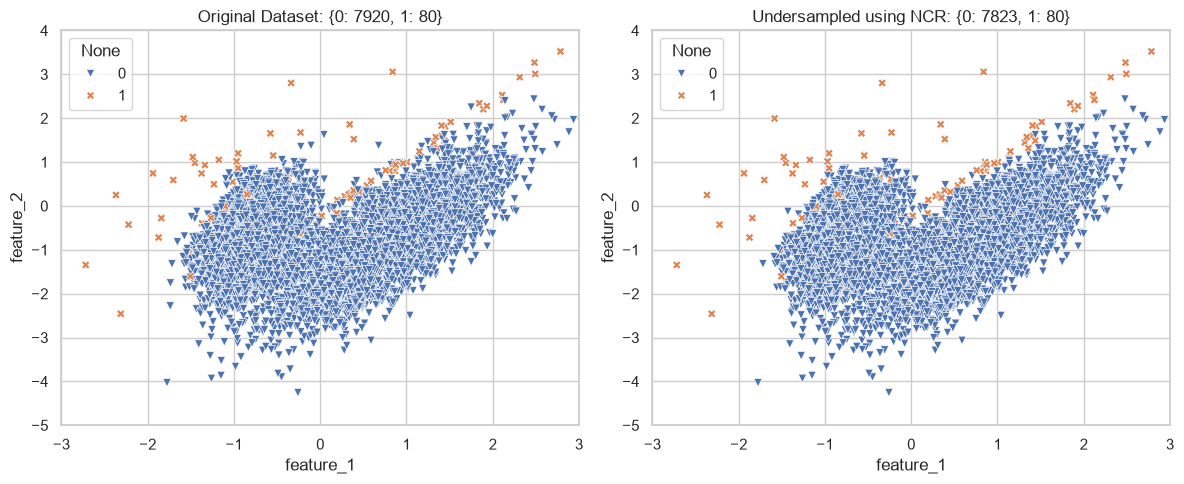

Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_ncr_a1_a2.png


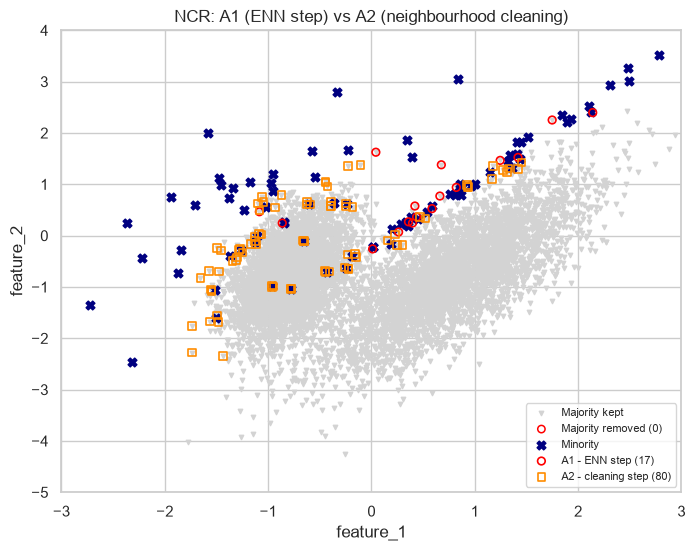

In [14]:
ncr = samplers["NCR"]
X_ncr, y_ncr, removed_ncr = run_cleaning("NCR", ncr)

# Tach phan bi xoa boi buoc 1 (ENN) va buoc 2 (lam sach lang gieng mau thieu so)
removed_a1 = removed_mask(ncr.edited_nearest_neighbours_, len(y_tr))
removed_a2 = removed_ncr & ~removed_a1
print("Lop duoc xet lam sach (classes_to_clean_):", [int(c) for c in ncr.classes_to_clean_])
print(f"A1 (buoc ENN): {removed_a1.sum()} mau | A2 (buoc lam sach lang gieng): {removed_a2.sum()} mau")

fig = compare_plot(X_ncr, y_ncr, "NCR")
save_figure(fig, "tv3_ncr_comparison")
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
plot_removed_samples(X_tr, y_tr, np.zeros(len(y_tr), dtype=bool), "NCR: A1 (ENN step) vs A2 (neighbourhood cleaning)", ax=ax)
ax.scatter(X_tr[removed_a1, 0], X_tr[removed_a1, 1], marker="o", s=30, facecolors="none",
           edgecolors="red", linewidths=1.2, label=f"A1 - ENN step ({removed_a1.sum()})")
ax.scatter(X_tr[removed_a2, 0], X_tr[removed_a2, 1], marker="s", s=30, facecolors="none",
           edgecolors="darkorange", linewidths=1.2, label=f"A2 - cleaning step ({removed_a2.sum()})")
ax.legend(loc="lower right", fontsize=8)
save_figure(fig, "tv3_ncr_a1_a2")
plt.show()

**Nhận xét NCR:** tổng số mẫu bị xóa tương đương ENN nhưng **phân bố khác**: phần A2 tập trung đúng quanh những mẫu thiểu số đang bị "lấn át", tức là nơi việc làm sạch có ích nhất cho Recall của lớp thiểu số.

## 3.9 Instance Hardness Threshold (IHT)

### 3.9.1 Lý thuyết

**Ý tưởng** (Smith, Martinez & Giraud-Carrier, 2014): thay vì dùng láng giềng, ta hỏi một **mô hình phân loại** xem mẫu nào "khó". Trong ẩn dụ: nhà vua hỏi một vị quan *"những người Capulet nào đã hòa lẫn với người Montague?"* rồi loại những người có tên trong danh sách.

**Độ khó của mẫu** (*instance hardness*) đối với bộ phân loại $h$:

$$IH_h(x_i, y_i) = 1 - p(y_i \mid x_i, h)$$

Mẫu có xác suất dự đoán **đúng lớp của chính nó** thấp là mẫu khó – nguyên nhân chủ yếu là **chồng lấn lớp** (class overlap).

**Cách imbalanced-learn thực hiện**

1. Ước lượng $p(y_i \mid x_i)$ bằng `cross_val_predict` (StratifiedKFold, `cv=5`) → mỗi mẫu được dự đoán bởi một mô hình **không** học trên chính nó.
2. Với lớp đa số, lấy ngưỡng $\tau$ là phân vị thứ $\left(1 - \frac{N_{\text{target}}}{N_{\text{maj}}}\right)\times 100$ của các xác suất $p$.
3. Chỉ giữ các mẫu đa số có $p \geq \tau$ (tức là xóa $N_{\text{maj}} - N_{\text{target}}$ mẫu khó nhất).

* Với `sampling_strategy='auto'` thì $N_{\text{target}} = N_{\text{min}}$ → dữ liệu được **cân bằng 1:1** – IHT là phương pháp duy nhất trong nhóm **kiểm soát được tỉ lệ đầu ra**, hành xử gần giống một *fixed method*.
* Kết quả phụ thuộc mạnh vào `estimator` (nhóm dùng `LogisticRegression`; mặc định của thư viện là `RandomForestClassifier`).
* Chi phí = $cv$ lần huấn luyện mô hình – nhanh với mô hình tuyến tính, phù hợp phát triển lặp nhanh như sách nhận xét.

IHT: {0: 7920, 1: 80} -> {0: 80, 1: 80} | loai 7840 mau | 0.034s


Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_iht_comparison.png


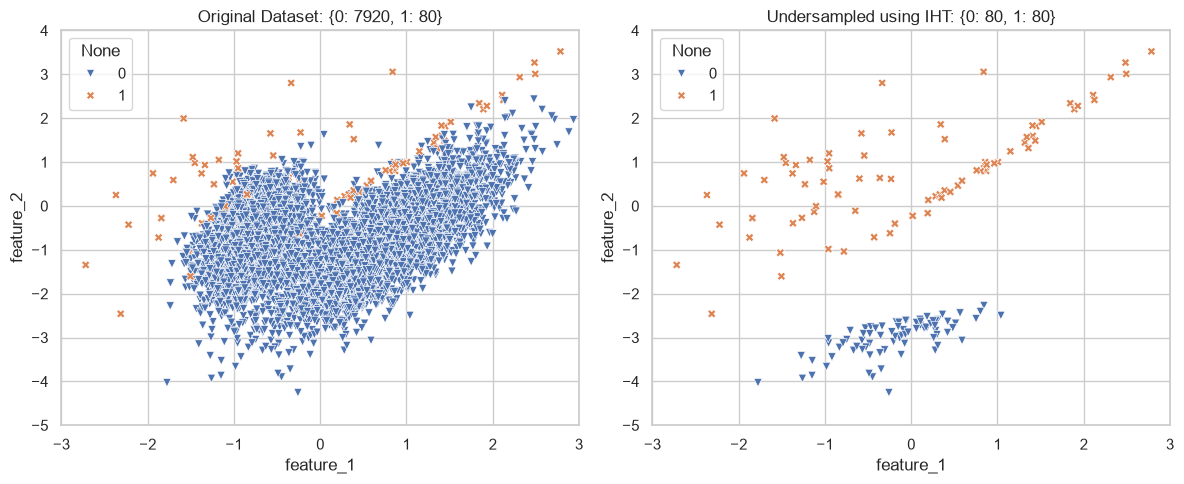

In [15]:
iht = samplers["IHT"]   # estimator = LogisticRegression, sampling_strategy='auto'
X_iht, y_iht, removed_iht = run_cleaning("IHT", iht)

fig = compare_plot(X_iht, y_iht, "IHT")
save_figure(fig, "tv3_iht_comparison")
plt.show()

### 3.9.2 Bản đồ độ khó và ngưỡng loại bỏ

Nguong tau = 0.999995 -> xoa mau da so co hardness > 4.786e-06
Ti le mau co cung quyet dinh giu/xoa voi imblearn: 99.83% (chenh lech nho do IHT tu sinh random state rieng cho cach chia fold)


Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_iht_hardness.png


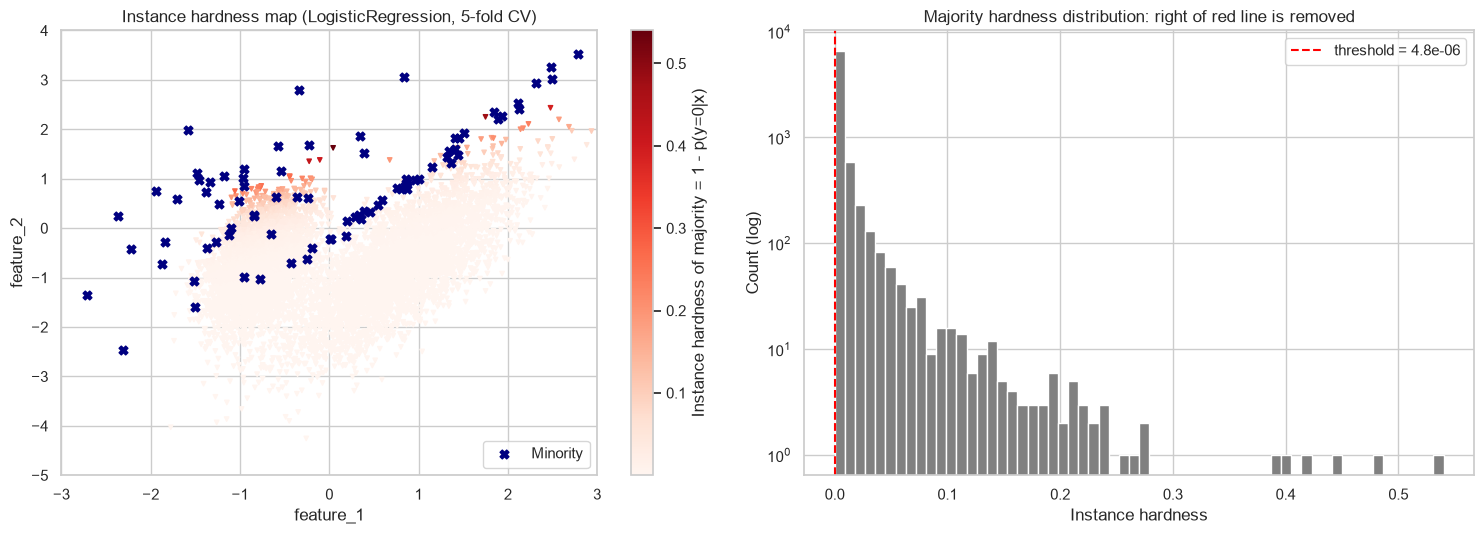

In [16]:
# Tinh lai instance hardness dung nhu cach IHT lam (xac suat cross-validated cua lop dung)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
proba = cross_val_predict(LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
                          X_tr, y_tr, cv=skf, method="predict_proba")
p_true = proba[np.arange(len(y_tr)), y_tr]
hardness = 1 - p_true

is_maj = y_tr == 0
tau = np.percentile(p_true[is_maj], (1 - (~is_maj).sum() / is_maj.sum()) * 100)
manual_removed_iht = is_maj & (p_true < tau)
print(f"Nguong tau = {tau:.6g} -> xoa mau da so co hardness > {1 - tau:.3e}")
print(f"Ti le mau co cung quyet dinh giu/xoa voi imblearn: {(manual_removed_iht == removed_iht).mean():.2%} "
      "(chenh lech nho do IHT tu sinh random state rieng cho cach chia fold)")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sc = axes[0].scatter(X_tr[is_maj, 0], X_tr[is_maj, 1], c=hardness[is_maj], cmap="Reds", s=10, marker="v")
axes[0].scatter(X_tr[~is_maj, 0], X_tr[~is_maj, 1], marker="X", s=40, c="navy", label="Minority")
fig.colorbar(sc, ax=axes[0], label="Instance hardness of majority = 1 - p(y=0|x)")
axes[0].set(xlim=XLIM, ylim=YLIM, xlabel="feature_1", ylabel="feature_2",
            title="Instance hardness map (LogisticRegression, 5-fold CV)")
axes[0].legend(loc="lower right")

axes[1].hist(hardness[is_maj], bins=60, color="gray")
axes[1].axvline(1 - tau, color="red", ls="--", label=f"threshold = {1 - tau:.1e}")
axes[1].set(yscale="log", xlabel="Instance hardness", ylabel="Count (log)",
            title="Majority hardness distribution: right of red line is removed")
axes[1].legend()
plt.tight_layout()
save_figure(fig, "tv3_iht_hardness")
plt.show()

### 3.9.3 Ảnh hưởng của `sampling_strategy`

Với `'auto'`, IHT xóa tới ~99% lớp đa số và chỉ giữ 80 mẫu "dễ nhất" – nằm rất xa vùng thiểu số. Mô hình học trên tập này sẽ đẩy biên quyết định quá xa. Thử các mức "nhẹ tay" hơn (với undersampling, `sampling_strategy` dạng số thực $= N_{\text{min}} / N_{\text{maj}}$ sau lấy mẫu):

Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_iht_strategies.png


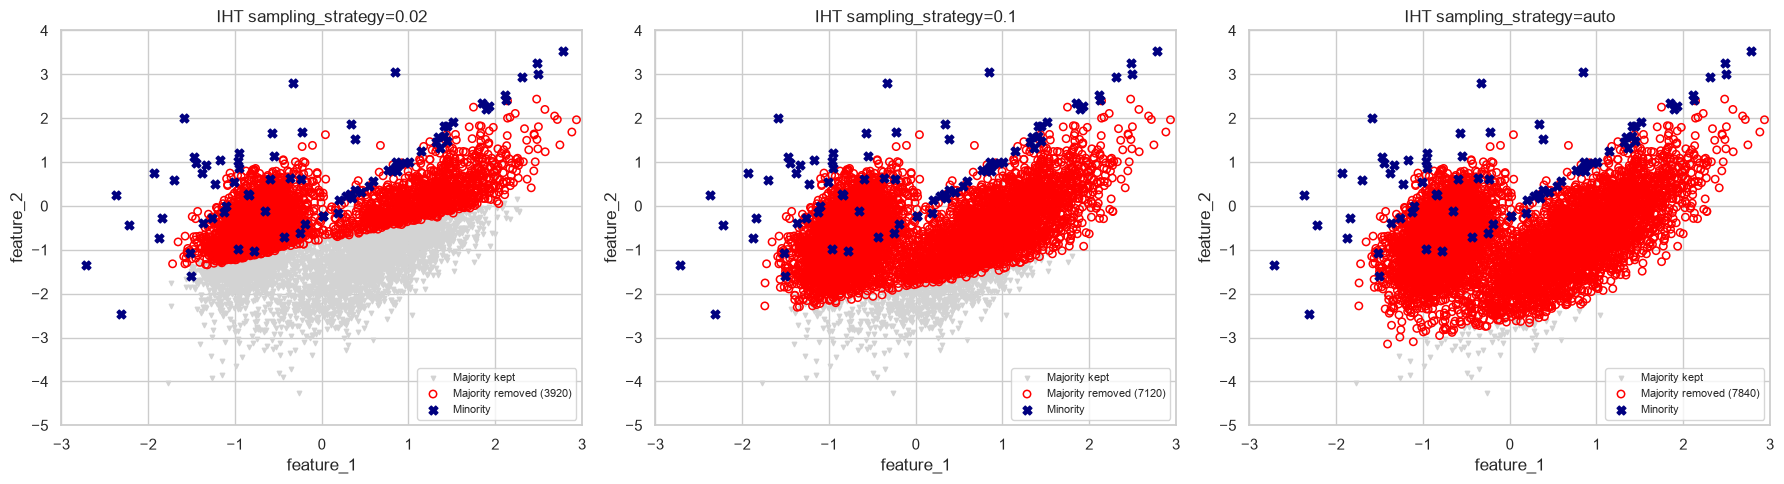

,Method,Model,PR-AUC,F2,Precision,Recall,Training Time (s),Resampled Shape
0,IHT (0.02),LogisticRegression,0.3927,0.2151,0.0548,0.8,0.0398,"{0: 4000, 1: 80}"
1,IHT (0.1),LogisticRegression,0.3439,0.1043,0.0228,1.0,0.0371,"{0: 800, 1: 80}"
2,IHT (auto),LogisticRegression,0.3923,0.0615,0.0129,1.0,0.0363,"{0: 80, 1: 80}"


In [17]:
rows = []
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, strategy in zip(axes, [0.02, 0.1, "auto"]):
    s = InstanceHardnessThreshold(
        estimator=LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
        sampling_strategy=strategy, random_state=RANDOM_STATE
    )
    res = evaluate_sampler_and_model(
        s, clone(models["LogisticRegression"]), X_tr, y_tr, X_te, y_te,
        method_name=f"IHT ({strategy})", model_name="LogisticRegression"
    )
    rows.append(res)
    plot_removed_samples(X_tr, y_tr, removed_mask(s, len(y_tr)), f"IHT sampling_strategy={strategy}", ax=ax)
plt.tight_layout()
save_figure(fig, "tv3_iht_strategies")
plt.show()

display(pd.DataFrame(rows).drop(columns=["Threshold"]))

**Nhận xét IHT:**

* Bản đồ độ khó cho thấy các mẫu đa số "khó" theo Logistic Regression nằm ở **mép trên của đám mây đa số**, sát các cụm thiểu số – đúng vùng chồng lấn. Phần lớn mẫu đa số có độ khó gần 0, nên ngưỡng giữ lại 1% mẫu dễ nhất cực kỳ sát 1.
* Với `'auto'`, IHT chỉ giữ 80 mẫu đa số **xa vùng thiểu số nhất** (đáy của đám mây) → mô hình kéo biên xuống tận đó: Recall = 1 nhưng Precision ≈ 1%.
* Ngay cả mức nhẹ `0.02` (giữ 4.000 mẫu) F2 vẫn thấp hơn khi không lấy mẫu (0,22 so với 0,34): trên dữ liệu này, lượng mẫu đa số bị xóa ở vùng chồng lấn chính là thông tin mà mô hình cần để giữ Precision.
* PR-AUC của Logistic Regression gần như không đổi (0,39 so với 0,41) → khả năng **xếp hạng** vẫn giữ, thứ thay đổi chủ yếu là **vị trí ngưỡng**. Vì vậy khi dùng IHT cần tinh chỉnh `sampling_strategy` và hiệu chuẩn xác suất / dời ngưỡng (Phần 1 của Leader), do phân phối lớp đã thay đổi mạnh.

## 3.10 So sánh tổng hợp: cơ chế mở rộng lề & làm sạch biên

### 3.10.1 Các mẫu bị loại bỏ bởi từng phương pháp

Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_all_methods_removed.png


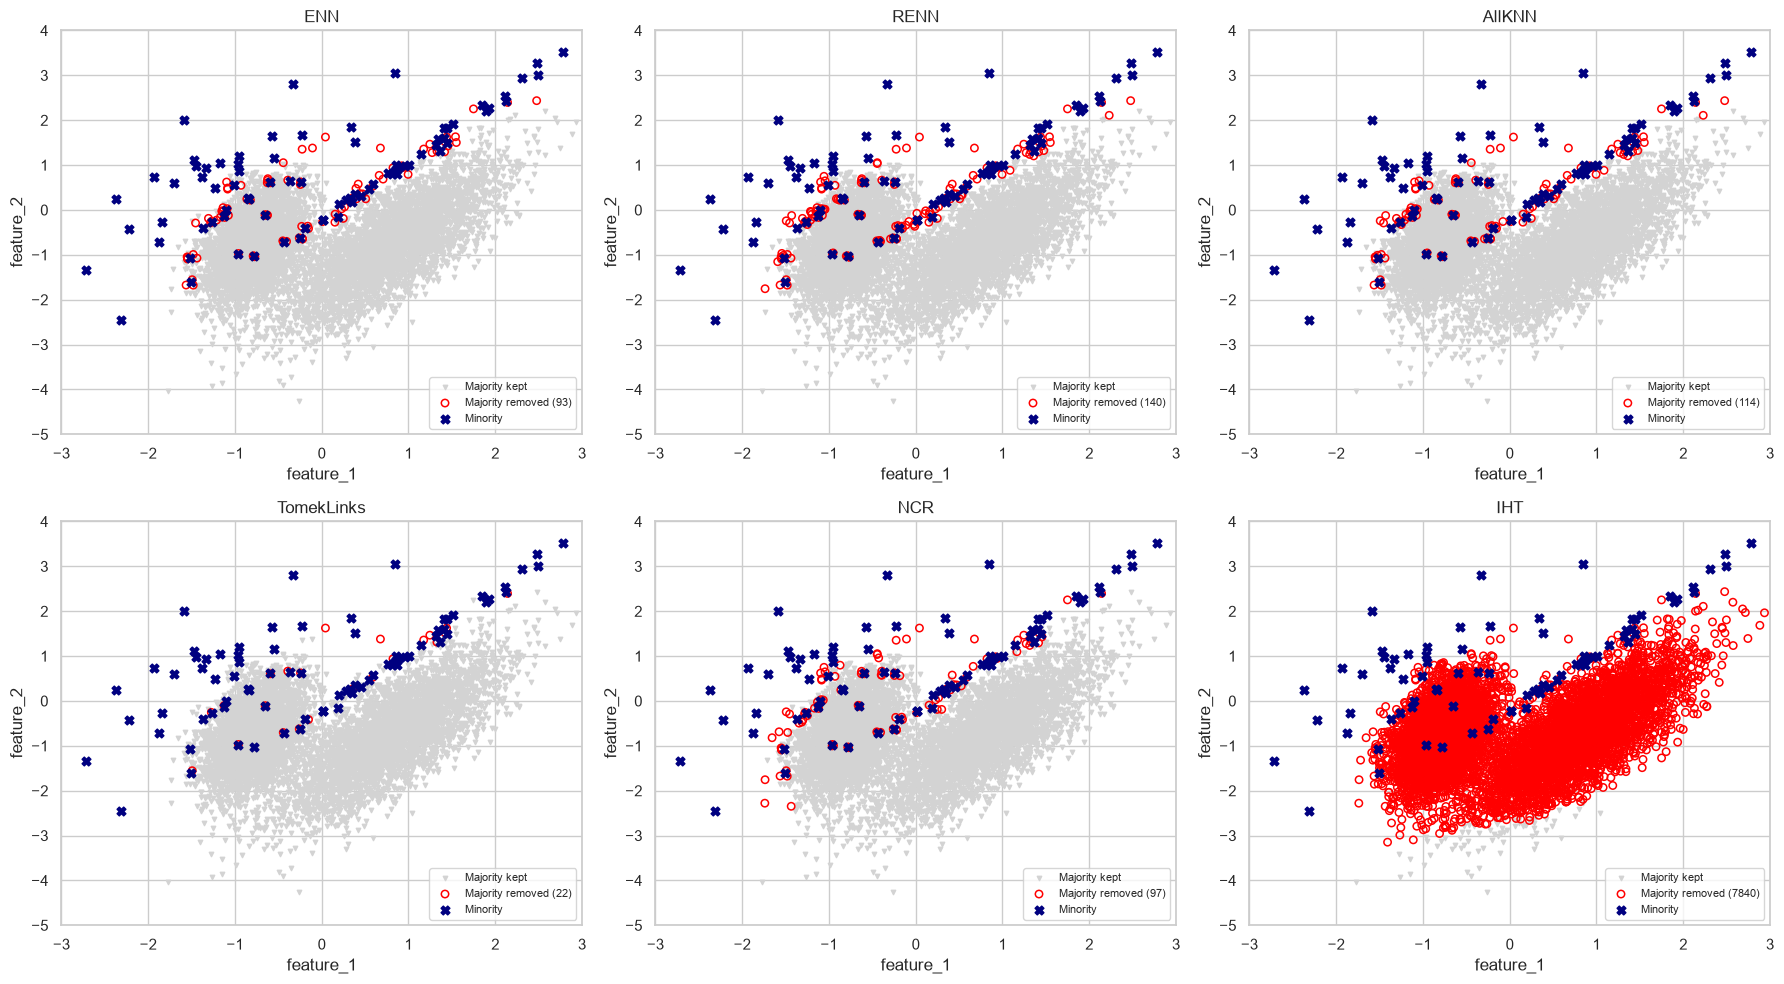

In [18]:
methods = ["ENN", "RENN", "AllKNN", "TomekLinks", "NCR", "IHT"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, name in zip(axes.ravel(), methods):
    plot_removed_samples(X_tr, y_tr, cleaning_results[name]["removed"], name, ax=ax)
plt.tight_layout()
save_figure(fig, "tv3_all_methods_removed")
plt.show()

### 3.10.2 Định lượng mức độ "mở rộng lề"

Đo **khoảng cách từ mỗi mẫu thiểu số tới mẫu đa số gần nhất** trước và sau khi làm sạch – nếu phương pháp thực sự mở rộng lề, khoảng cách này phải tăng.

Đã lưu bảng số liệu tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\tables\tv3_cleaning_summary.csv


,Method,Majority after,Minority after,Majority removed,% majority removed,Imbalance ratio,Mean min-dist minority->majority,Resampling time (s)
0,NoSampling,7920,80,0,0.00,1:99,0.2520,0.0000
1,ENN,7827,80,93,1.17,1:98,0.3517,0.0169
2,RENN,7780,80,140,1.77,1:97,0.3771,0.0832
3,AllKNN,7806,80,114,1.44,1:98,0.3645,0.0347
4,TomekLinks,7898,80,22,0.28,1:99,0.2778,0.0128
5,NCR,7823,80,97,1.22,1:98,0.3521,0.0248
6,IHT,80,80,7840,98.99,1:1,3.3875,0.0338


Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_margin_boxplot.png


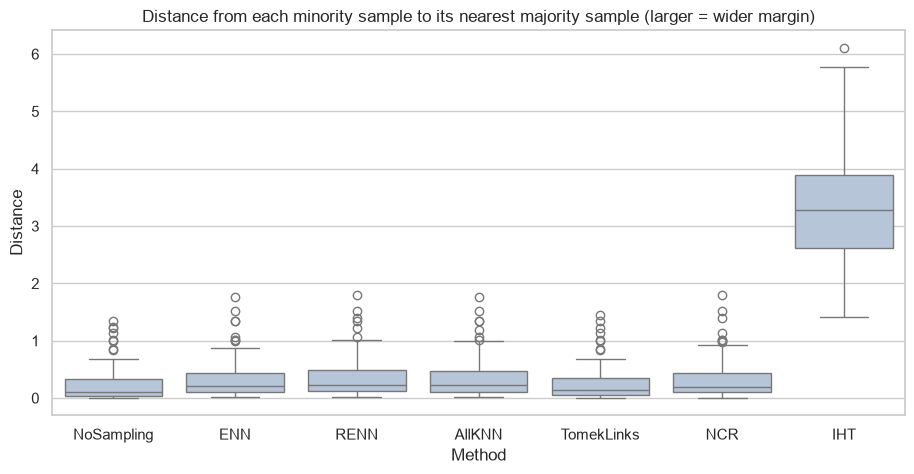

In [19]:
margin_rows, summary_rows = [], []
for name in ["NoSampling"] + methods:
    if name == "NoSampling":
        X_res, y_res, elapsed = X_tr, y_tr, 0.0
    else:
        r = cleaning_results[name]
        X_res, y_res, elapsed = r["X_res"], r["y_res"], r["time"]
    dist = nearest_opposite_distance(X_res, y_res)
    margin_rows += [{"Method": name, "Distance": d} for d in dist]
    n_maj = int((y_res == 0).sum())
    summary_rows.append({
        "Method": name,
        "Majority after": n_maj,
        "Minority after": int((y_res == 1).sum()),
        "Majority removed": int((y_tr == 0).sum() - n_maj),
        "% majority removed": round(100 * (1 - n_maj / (y_tr == 0).sum()), 2),
        "Imbalance ratio": f"1:{n_maj / max((y_res == 1).sum(), 1):.0f}",
        "Mean min-dist minority->majority": round(dist.mean(), 4),
        "Resampling time (s)": round(elapsed, 4)
    })

summary_df = pd.DataFrame(summary_rows)
save_table(summary_df, "tv3_cleaning_summary")
display(summary_df)

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=pd.DataFrame(margin_rows), x="Method", y="Distance", ax=ax, color="lightsteelblue")
ax.set_title("Distance from each minority sample to its nearest majority sample (larger = wider margin)")
save_figure(fig, "tv3_margin_boxplot")
plt.show()

### 3.10.3 Biên quyết định sau khi làm sạch

Huấn luyện Logistic Regression và Random Forest (cấu hình chuẩn `get_benchmark_models()`) trên từng tập đã làm sạch, vẽ bằng hàm chung `plot_decision_boundary()`:

Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_decision_boundary_LogisticRegression.png


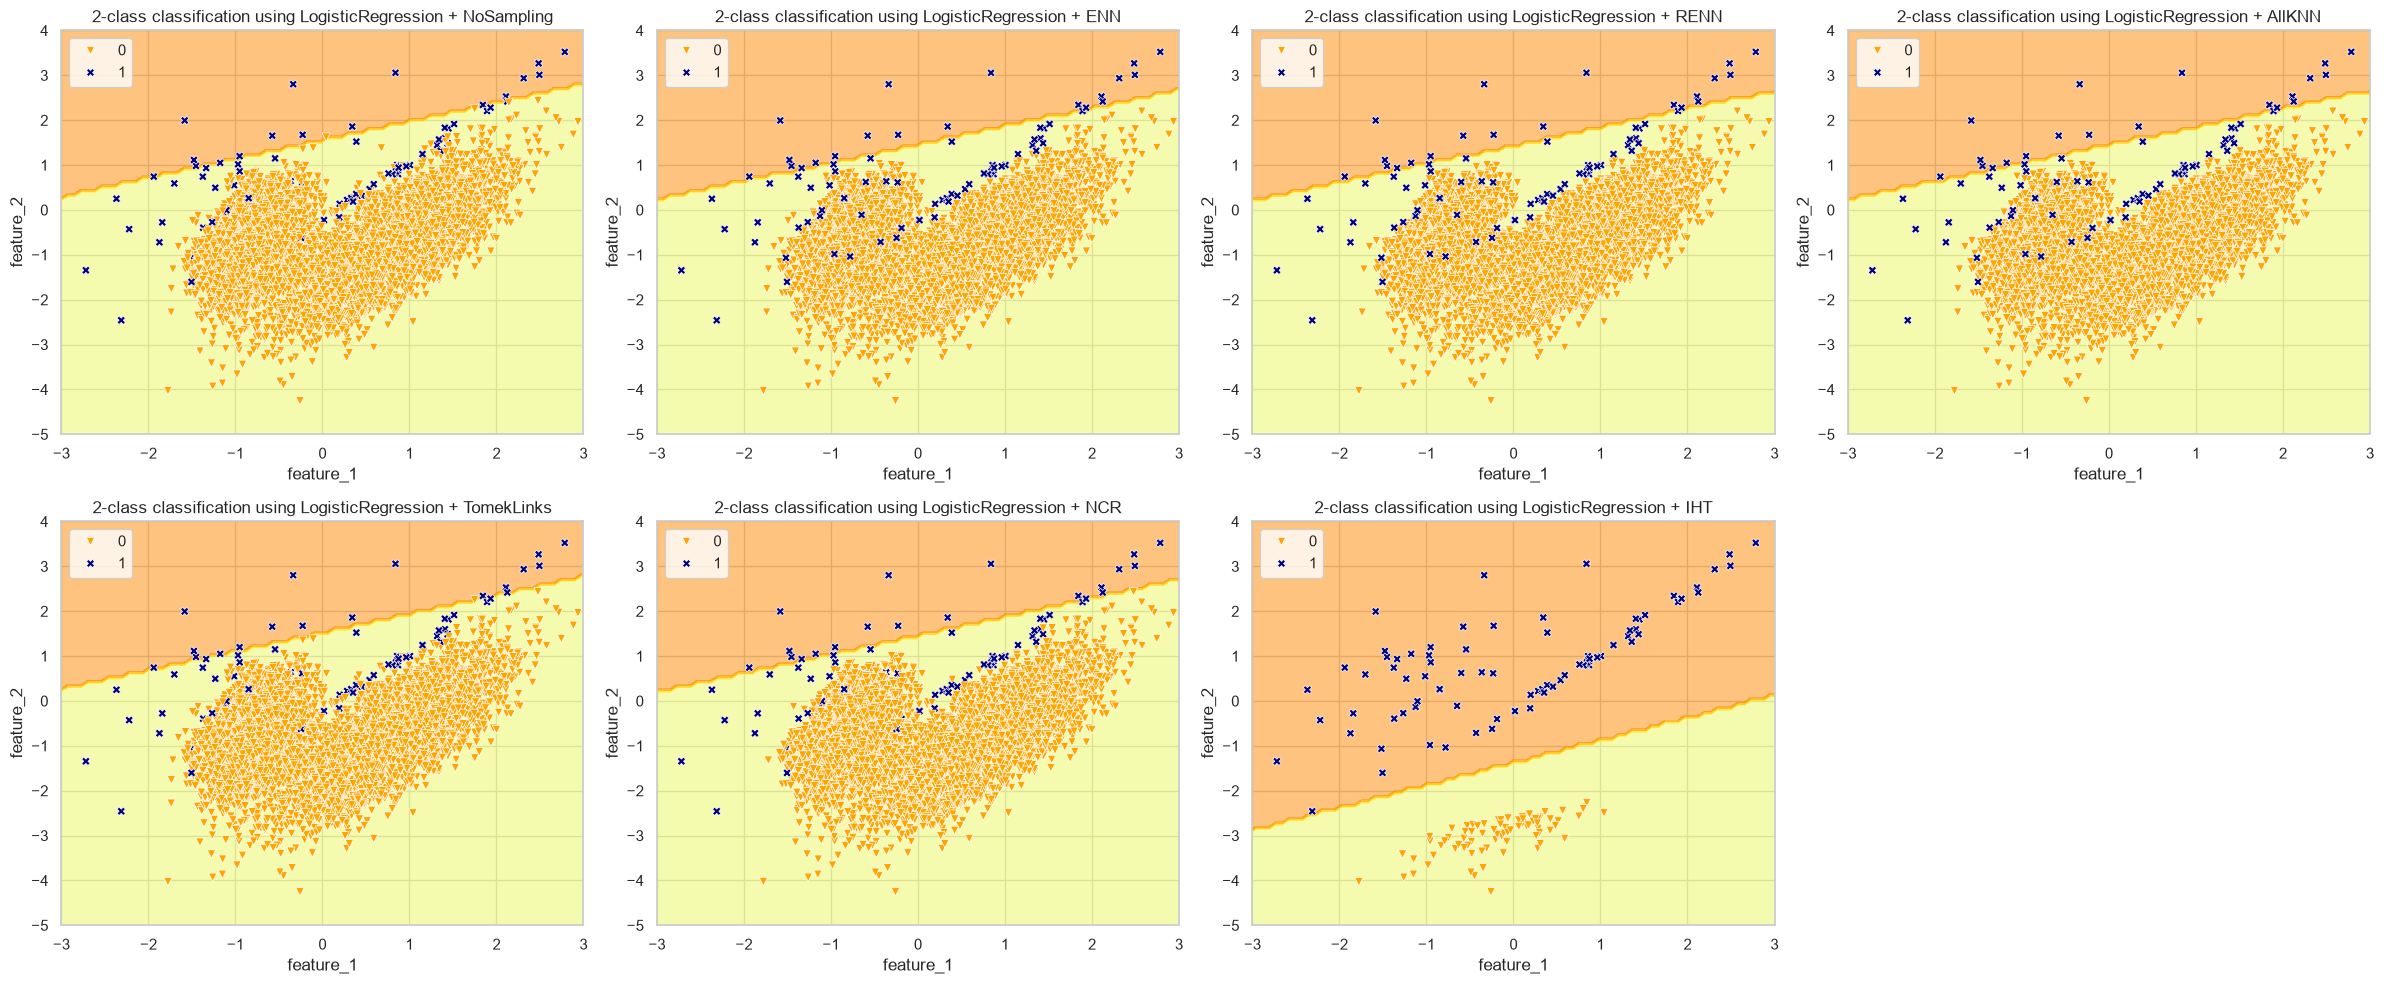

Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_decision_boundary_RandomForest.png


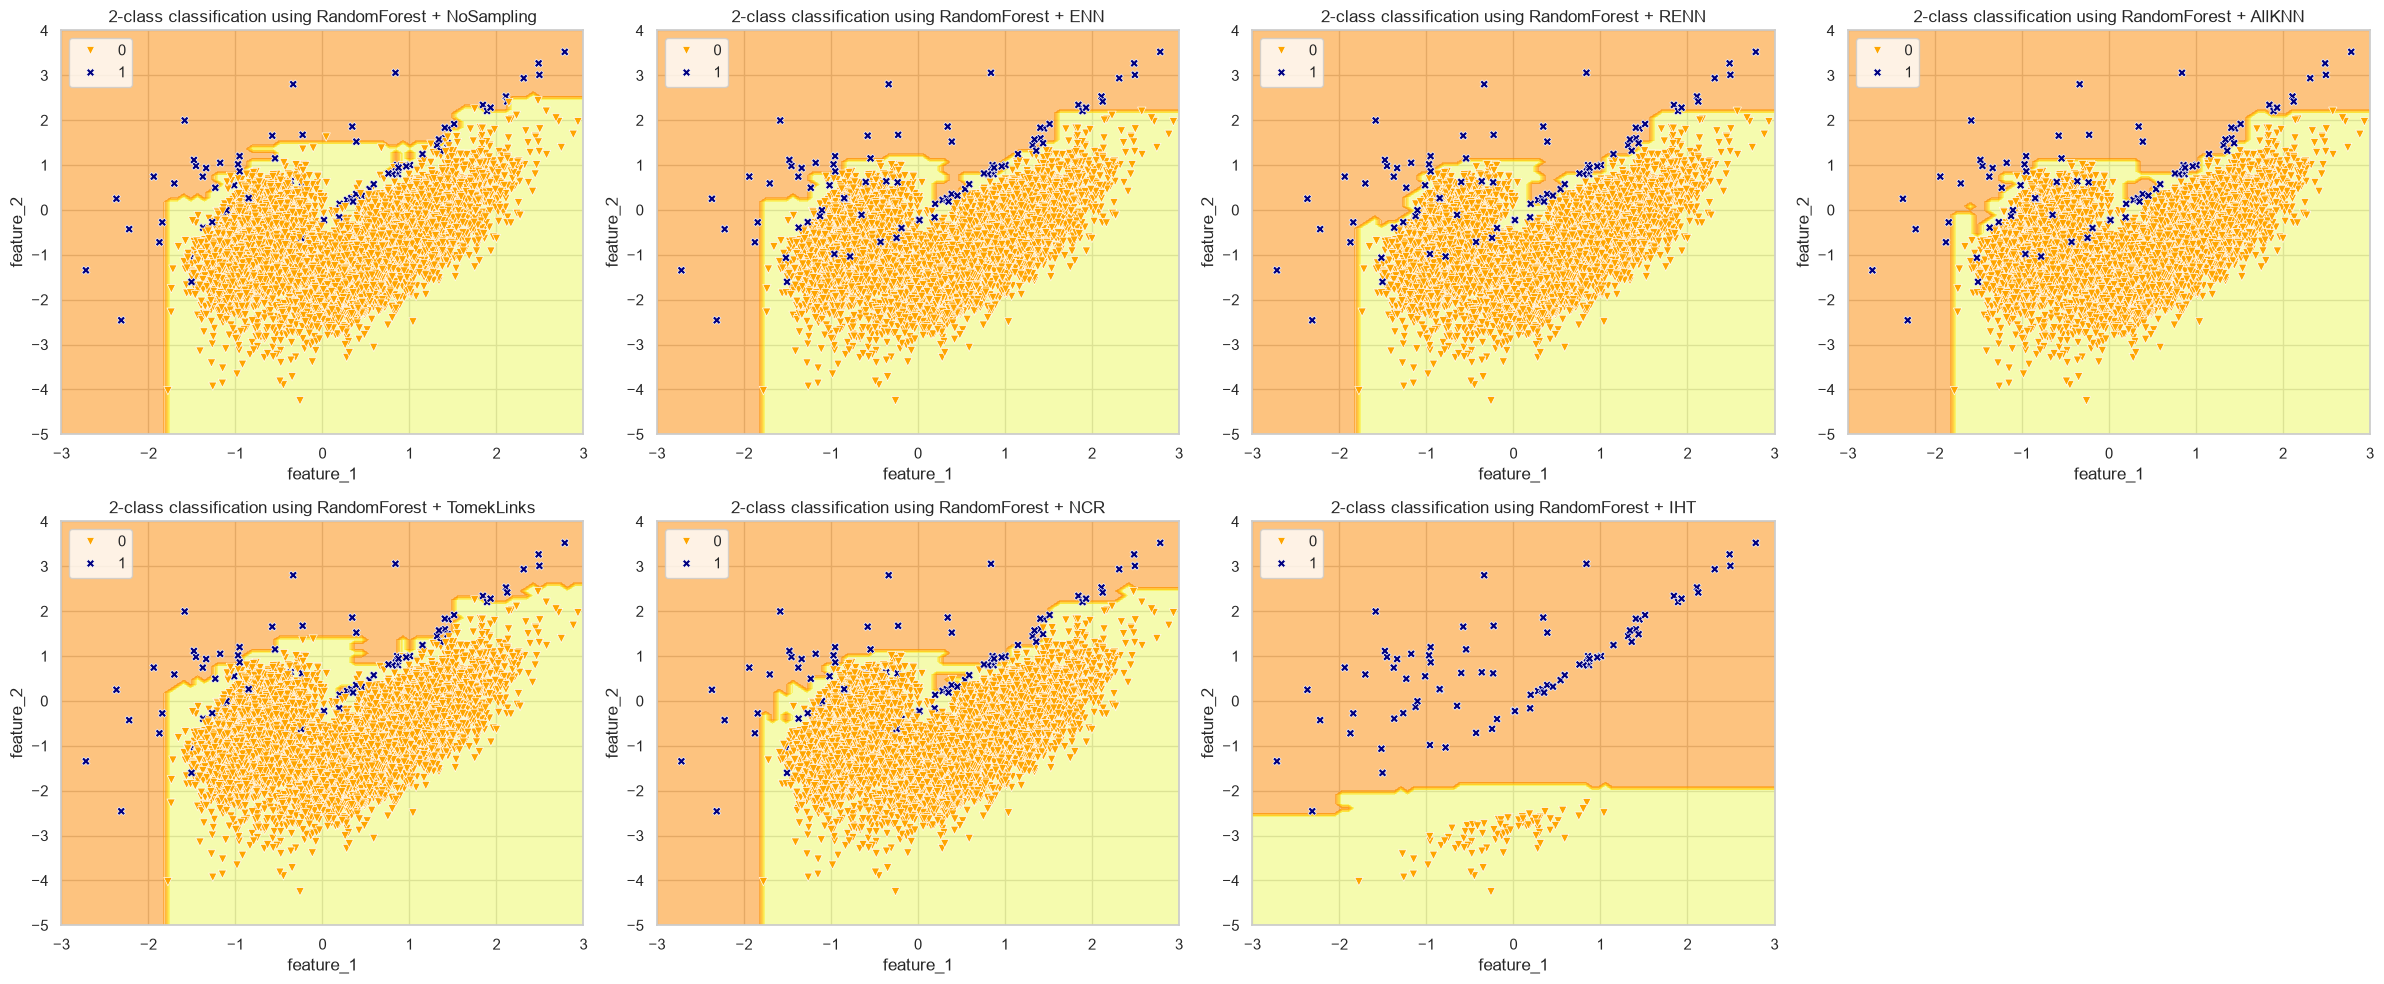

In [20]:
fitted = {}
for model_name in ["LogisticRegression", "RandomForest"]:
    fig, axes = plt.subplots(2, 4, figsize=(24, 10))
    for ax, name in zip(axes.ravel(), ["NoSampling"] + methods):
        if name == "NoSampling":
            X_res, y_res = X_tr, y_tr
        else:
            X_res, y_res = cleaning_results[name]["X_res"], cleaning_results[name]["y_res"]
        clf = clone(models[model_name]).fit(X_res, y_res)
        fitted[(model_name, name)] = clf
        plot_decision_boundary(X_res, y_res, clf, f"{model_name} + {name}", ax=ax)
        ax.set_xlim(*XLIM)
        ax.set_ylim(*YLIM)
    axes.ravel()[-1].axis("off")
    plt.tight_layout()
    save_figure(fig, f"tv3_decision_boundary_{model_name}")
    plt.show()

### 3.10.4 Đánh giá nhanh trên tập test synthetic

Đo bằng hàm chuẩn `evaluate_sampler_and_model()` (PR-AUC, F2, Precision, Recall, thời gian = lấy mẫu + huấn luyện). Đây chỉ là kiểm tra nhanh trên dữ liệu 2D (tập test chỉ có **20 mẫu thiểu số** nên chỉ số dao động mạnh); benchmark đầy đủ trên dữ liệu thực tế do Phần 4 thực hiện.

Đã lưu đồ thị tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\figures\tv3_pr_curves_synthetic.png


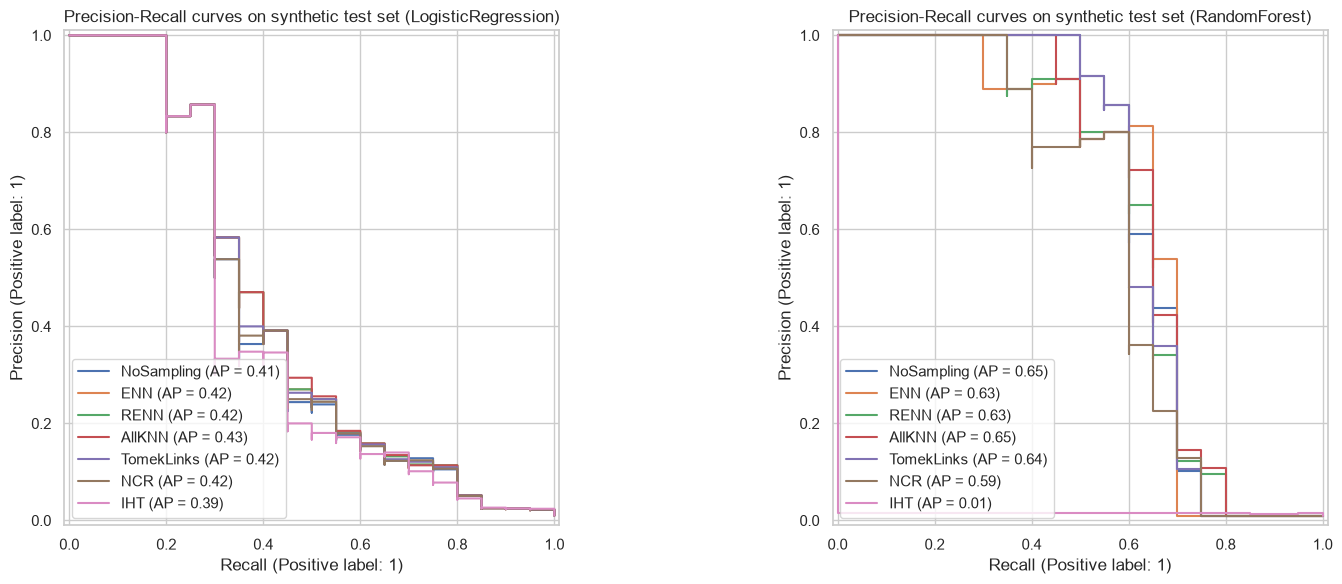

Đã lưu bảng số liệu tại: D:\pattern_recognition\PR_Seminar_Undersampling\outputs\tables\tv3_cleaning_metrics_synthetic.csv


PR-AUC                              F2               \
Model      LogisticRegression RandomForest LogisticRegression RandomForest   
Method                                                                       
NoSampling             0.4140       0.6477             0.3448       0.5978   
ENN                    0.4240       0.6292             0.3409       0.6316   
RENN                   0.4240       0.6279             0.3409       0.6061   
AllKNN                 0.4257       0.6468             0.3409       0.6250   
TomekLinks             0.4197       0.6385             0.3448       0.6383   
NCR                    0.4152       0.5889             0.3409       0.6250   
IHT                    0.3923       0.0149             0.0615       0.0517   

                    Precision                          Recall               
Model      LogisticRegression RandomForest LogisticRegression RandomForest  
Method                                                                      
NoSampling             0.8571       0.9167                0.3         0.55  
ENN                    0.7500       0.8000                0.3         0.60  
RENN                   0.7500       0.6316                0.3         0.60  
AllKNN                 0.7500       0.7500                0.3         0.60  
TomekLinks             0.8571       0.8571                0.3         0.60  
NCR                    0.7500       0.7500                0.3         0.60  
IHT                    0.0129       0.0108                1.0         1.00

In [21]:
metric_rows = []
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, model_name in zip(axes, ["LogisticRegression", "RandomForest"]):
    for name in ["NoSampling"] + methods:
        clf = clone(models[model_name])
        metric_rows.append(evaluate_sampler_and_model(
            samplers[name], clf, X_tr, y_tr, X_te, y_te, method_name=name, model_name=model_name
        ))
        plot_pr_curve(clf, X_te, y_te, name=name, ax=ax)
    ax.set_title(f"Precision-Recall curves on synthetic test set ({model_name})")
plt.tight_layout()
save_figure(fig, "tv3_pr_curves_synthetic")
plt.show()

metrics_df = pd.DataFrame(metric_rows)
save_table(metrics_df.drop(columns=["Resampled Shape"]), "tv3_cleaning_metrics_synthetic")
display(metrics_df.pivot(index="Method", columns="Model", values=["PR-AUC", "F2", "Precision", "Recall"])
        .reindex(["NoSampling"] + methods))

### 3.10.5 Nhận xét tổng hợp

* **Mức độ làm sạch:** TomekLinks < ENN ≈ NCR < AllKNN < RENN ≪ IHT. Năm phương pháp dựa trên láng giềng chỉ xóa 0,3% – 2% lớp đa số → tỉ lệ vẫn ~1:98, **không cân bằng** được dữ liệu; chỉ IHT đưa về 1:1.
* **Mở rộng lề:** khoảng cách trung bình từ mẫu thiểu số tới mẫu đa số gần nhất tăng theo đúng thứ tự mức độ làm sạch – minh chứng định lượng cho cơ chế "mở rộng lề".
* **Biên quyết định:** với Logistic Regression, các phương pháp dựa trên láng giềng gần như **không làm dịch biên** vì lượng mẫu xóa quá nhỏ so với 7.900 mẫu đa số; Random Forest (mô hình cục bộ) nhạy hơn – vùng dự đoán thiểu số rộng ra quanh các cụm thiểu số, Recall tăng. IHT đẩy biên đi quá xa → Recall = 1 nhưng Precision ≈ 1%.
* **PR-AUC** của 5 phương pháp dựa trên láng giềng dao động quanh mức của NoSampling (±0,06): chúng chủ yếu **dịch biên/ngưỡng** chứ không cải thiện rõ khả năng xếp hạng. Riêng IHT + Random Forest có PR-AUC sụp xuống ~0,01: chỉ còn 80 mẫu đa số ở xa nên cây không còn dữ liệu để phân biệt hai lớp trong vùng chồng lấn. Điều này khớp với kết luận của sách: không có kỹ thuật nào thắng tuyệt đối, cần thử nghiệm trên chính dữ liệu của mình.
* **Thời gian:** cả 6 phương pháp đều chạy dưới 0,1 giây trên 8.000 mẫu 2D; RENN, AllKNN đắt nhất trong họ láng giềng do lặp nhiều lần (sách ghi nhận AllKNN chậm khi chạy trên 1 triệu mẫu).

*(Số liệu cụ thể xem bảng `outputs/tables/tv3_cleaning_summary.csv` và `tv3_cleaning_metrics_synthetic.csv`.)*

## 3.11 Tóm tắt các bài báo gốc

### 3.11.1 Wilson (1972) – *Asymptotic Properties of Nearest Neighbor Rules Using Edited Data*
*IEEE Trans. Systems, Man, and Cybernetics, SMC-2(3), 408–421.* — **Nền tảng của ENN**

* **Vấn đề:** luật 1-NN rất nhạy với các mẫu huấn luyện nằm trong vùng chồng lấn: một điểm "lạc" sang vùng lớp kia sẽ khiến mọi điểm mới ở gần nó bị phân loại sai.
* **Đề xuất:** quy trình hai bước – (1) **biên tập** (*edit*) tập huấn luyện bằng cách xóa mọi mẫu bị luật k-NN (k = 3) phân loại sai; (2) phân loại điểm mới bằng 1-NN trên tập đã biên tập.
* **Kết quả:** phân tích tiệm cận cho thấy luật NN trên dữ liệu đã biên tập có rủi ro tiệm cận gần với rủi ro Bayes hơn so với 1-NN thông thường; tập biên tập có biên giữa các lớp "sạch" và trơn hơn.
* **Liên hệ:** chính là `EditedNearestNeighbours`; điểm khác là imbalanced-learn chỉ biên tập lớp đa số để không làm mất thêm mẫu thiểu số.

### 3.11.2 Tomek (1976a) – *Two Modifications of CNN*
*IEEE Trans. Systems, Man, and Cybernetics, SMC-6(11), 769–772.* — **Nguồn gốc của Tomek Links**

* **Vấn đề:** thuật toán Condensed Nearest Neighbor của Hart (1968) giữ lại tập con nhất quán nhưng không ưu tiên các điểm gần biên, nên tập rút gọn vẫn còn nhiều điểm không cần thiết và phụ thuộc vào thứ tự duyệt.
* **Đề xuất:** hai cải tiến của CNN nhằm chọn các điểm nằm sát biên quyết định; trong đó định nghĩa cặp điểm khác lớp là láng giềng gần nhất của nhau – về sau được gọi là **Tomek link** – làm dấu hiệu nhận biết điểm biên/nhiễu.
* **Ý nghĩa:** Tomek link trở thành công cụ làm sạch biên kinh điển: Kubat & Matwin (1997) dùng nó trong One-Sided Selection (Phần 2), Batista và cộng sự (2003, 2004) dùng sau SMOTE (SMOTETomek – Phần 4).

### 3.11.3 Tomek (1976b) – *An Experiment with the Edited Nearest-Neighbor Rule*
*IEEE Trans. Systems, Man, and Cybernetics, SMC-6(6), 448–452.* — **Nguồn gốc của RENN và AllKNN**

* **Vấn đề:** luật biên tập của Wilson chỉ chạy một lượt với một giá trị k cố định.
* **Đề xuất & thực nghiệm:** khảo sát thực nghiệm luật của Wilson và hai biến thể: **lặp lại** việc biên tập cho tới khi không còn điểm nào bị xóa (→ RENN) và biên tập bằng **tất cả các k-NN** với k = 1…K, xóa điểm nếu bị phân loại sai ở bất kỳ k nào (→ AllKNN).
* **Kết quả:** các biến thể lặp làm sạch vùng chồng lấn triệt để hơn, giúp biên quyết định của luật NN trơn hơn; đổi lại chi phí tính toán tăng.

### 3.11.4 Laurikkala (2001) – *Improving Identification of Difficult Small Classes by Balancing Class Distribution*
*Artificial Intelligence in Medicine (AIME 2001), LNCS 2101, 63–66.* — **Nguồn gốc của NCR**

* **Bối cảnh:** dữ liệu y khoa thường có các lớp nhỏ nhưng quan trọng (bệnh hiếm), bị bộ phân loại bỏ qua.
* **Đề xuất:** Neighbourhood Cleaning Rule – ưu tiên **làm sạch dữ liệu** thay vì chỉ giảm kích thước như One-Sided Selection: (1) dùng ENN (k = 3) xóa mẫu nhiễu của các lớp còn lại; (2) với mỗi mẫu của lớp quan tâm bị 3-NN phân loại sai, xóa các láng giềng thuộc lớp khác; chỉ xét các lớp có kích thước ≥ một nửa lớp quan tâm.
* **Kết quả:** trên các bộ dữ liệu thực tế, NCR cải thiện rõ khả năng nhận diện (độ nhạy – *true positive rate*) của lớp nhỏ so với dữ liệu gốc, đồng thời tốt hơn hoặc ngang với One-Sided Selection và oversampling ngẫu nhiên, mà không làm giảm đáng kể độ chính xác chung.

### 3.11.5 Smith, Martinez & Giraud-Carrier (2014) – *An Instance Level Analysis of Data Complexity*
*Machine Learning, 95(2), 225–256.* — **Nguồn gốc của IHT**

* **Vấn đề:** các thước đo độ phức tạp truyền thống mô tả *toàn bộ tập dữ liệu*, không cho biết *mẫu nào* gây khó cho việc học.
* **Đề xuất:** định nghĩa **instance hardness** – xác suất một mẫu bị phân loại sai, ước lượng bằng cách lấy trung bình trên nhiều thuật toán học khác nhau: $IH(x_i, y_i) = 1 - \frac{1}{|\mathcal{L}|}\sum_{l \in \mathcal{L}} p(y_i \mid x_i, l)$; kèm theo một bộ *hardness measures* có thể tính mà không cần huấn luyện (ví dụ *k-Disagreeing Neighbors*, *class likelihood*…).
* **Kết quả:** phân tích trên nhiều bộ dữ liệu và thuật toán cho thấy một tỉ lệ đáng kể mẫu bị *hầu hết* thuật toán phân loại sai, và **chồng lấn lớp** là yếu tố chính tạo nên độ khó; việc xử lý riêng các mẫu khó (lọc bỏ hoặc giảm trọng số khi huấn luyện) giúp cải thiện độ chính xác.
* **Liên hệ:** `InstanceHardnessThreshold` là phiên bản đơn giản – chỉ dùng **một** bộ phân loại với xác suất cross-validated, và chỉ lọc lớp đa số.

## 3.12 Kết luận & khuyến nghị sử dụng

| Tình huống | Gợi ý |
|---|---|
| Dữ liệu có nhiều nhiễu / chồng lấn, muốn giữ gần như toàn bộ dữ liệu | ENN (`kind_sel='mode'`) hoặc NCR |
| Muốn làm sạch biên mạnh hơn | RENN, AllKNN (chú ý chi phí khi dữ liệu lớn) |
| Chỉ muốn "gọt" nhẹ đúng các điểm trên biên | Tomek Links |
| Cần cân bằng tỉ lệ nhanh, phát triển lặp nhanh | IHT (tinh chỉnh `sampling_strategy` và `estimator`) |
| Dữ liệu mất cân bằng nặng, cleaning xóa quá ít | Kết hợp oversampling: SMOTEENN, SMOTETomek (Phần 4) |

**Lưu ý thực hành**

1. Luôn chia train/test **trước** khi làm sạch và chỉ áp dụng trên tập train (hoặc dùng `imblearn.pipeline.Pipeline` trong cross-validation).
2. Các phương pháp dựa trên láng giềng cần **chuẩn hóa đặc trưng**; với dữ liệu nhiều chiều, khoảng cách kém ý nghĩa hơn nên hiệu quả có thể giảm.
3. Làm sạch có thể xóa nhầm các mẫu đa số **hợp lệ nhưng nằm sát biên** → mô hình tăng Recall nhưng giảm Precision; cần đánh giá bằng PR-AUC/F2 thay vì Accuracy.
4. Khi tỉ lệ lớp thay đổi nhiều (đặc biệt IHT), xác suất dự đoán bị lệch → cần **hiệu chuẩn xác suất / dời ngưỡng** (Phần 1).

## Tài liệu tham khảo

1. K. Abhishek, M. Abdelaziz, *Machine Learning for Imbalanced Data*, Packt, 2023 – Chương 3: Undersampling Methods.
2. D. L. Wilson, "Asymptotic Properties of Nearest Neighbor Rules Using Edited Data," *IEEE Trans. SMC*, vol. SMC-2, no. 3, pp. 408–421, 1972.
3. I. Tomek, "An Experiment with the Edited Nearest-Neighbor Rule," *IEEE Trans. SMC*, vol. SMC-6, no. 6, pp. 448–452, 1976.
4. I. Tomek, "Two Modifications of CNN," *IEEE Trans. SMC*, vol. SMC-6, no. 11, pp. 769–772, 1976.
5. J. Laurikkala, "Improving Identification of Difficult Small Classes by Balancing Class Distribution," *AIME 2001*, LNCS 2101, pp. 63–66, 2001.
6. M. R. Smith, T. Martinez, C. Giraud-Carrier, "An Instance Level Analysis of Data Complexity," *Machine Learning*, vol. 95, no. 2, pp. 225–256, 2014.
7. M. Kubat, S. Matwin, "Addressing the Curse of Imbalanced Training Sets: One-Sided Selection," *ICML*, 1997.
8. G. E. A. P. A. Batista, R. C. Prati, M. C. Monard, "A Study of the Behavior of Several Methods for Balancing Machine Learning Training Data," *SIGKDD Explorations*, vol. 6, no. 1, pp. 20–29, 2004.
9. imbalanced-learn documentation – Under-sampling: https://imbalanced-learn.org/stable/under_sampling.html